### Simple Sweetviz demonstration
Link to [Sweetviz source information](https://github.com/fbdesignpro/sweetviz)

Install the latest stable version of Sweetviz

In [ ]:
%pip install sweetviz --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.1/15.1 MB 45.6 MB/s eta 0:00:00


**ONLY IF ABSOLUTELY NECESSARY**: Restart the Colab session via `os.kill`

In [ ]:
# import os
# os.kill(os.getpid(), 9)

Import packages and confirm installed versions

In [ ]:
import numpy
numpy.__version__

'2.1.3'

In [ ]:
import sweetviz
sweetviz.__version__

'2.3.3'

Retrieve the assigned dataset

In [ ]:
import pandas as pd

100%|██████████| 391k/391k [00:00<00:00, 60.9MB/s]

Extracting files...
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4249 entries, 0 to 4248
Data columns (total 24 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   TEAM        4249 non-null   object 
 1   CONF        4249 non-null   object 
 2   G           4249 non-null   int64  
 3   W           4249 non-null   int64  
 4   ADJOE       4249 non-null   float64
 5   ADJDE       4249 non-null   float64
 6   BARTHAG     4249 non-null   float64
 7   EFG_O       4249 non-null   float64
 8   EFG_D       4249 non-null   float64
 9   TOR         4249 non-null   float64
 10  TORD        4249 non-null   float64
 11  ORB         4249 non-null   float64
 12  DRB         4249 non-null   float64
 13  FTR         4249 non-null   float64
 14  FTRD        4249 non-null   float64
 15  2P_O        4249 non-null   float64
 16  2P_D        4249 non-null   float64
 17  3P_O        4249 non-null   float64
 18  3P_D        4249 non-null   float64
 19  ADJ_T  

,Missing Values,Percentage Missing
TEAM,0,0.0
CONF,0,0.0
G,0,0.0
W,0,0.0
ADJOE,0,0.0
ADJDE,0,0.0
BARTHAG,0,0.0
EFG_O,0,0.0
EFG_D,0,0.0
TOR,0,0.0



Number of duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
G,4249.0,30.753589,3.758512,5.000,29.0000,31.0000,33.0000,40.0000
W,4249.0,16.177924,6.497419,0.000,11.0000,16.0000,21.0000,38.0000
ADJOE,4249.0,103.625865,7.402858,76.600,98.6000,103.3000,108.3000,130.6000
ADJDE,4249.0,103.627418,6.563856,84.000,99.0000,103.8000,108.3000,125.3000
BARTHAG,4249.0,0.493439,0.255445,0.005,0.2812,0.4725,0.7153,0.9842
EFG_O,4249.0,50.006354,3.080054,39.200,48.0000,50.0000,52.0000,61.0000
EFG_D,4249.0,50.197670,2.845484,39.600,48.3000,50.2000,52.1000,60.1000
TOR,4249.0,18.441469,2.160366,11.900,17.0000,18.3000,19.8000,27.1000
TORD,4249.0,18.373923,2.312224,10.200,16.8000,18.3000,19.8000,28.5000
ORB,4249.0,29.302283,4.201140,14.400,26.5000,29.4000,32.1000,43.6000


...

,count
CONF,
ACC,180
A10,172
SEC,170
B10,168
CUSA,156
SB,145
MAC,144
Slnd,142
OVC,138



Postseason outcomes:


,count
POSTSEASON,
NaN,3433
R64,384
R32,192
S16,96
E8,48
R68,48
F4,24
2ND,12
Champions,12



Observations by season:


,count
YEAR,
2013,347
2014,351
2015,351
2016,351
2017,351
2018,351
2019,353
2021,347
2022,358


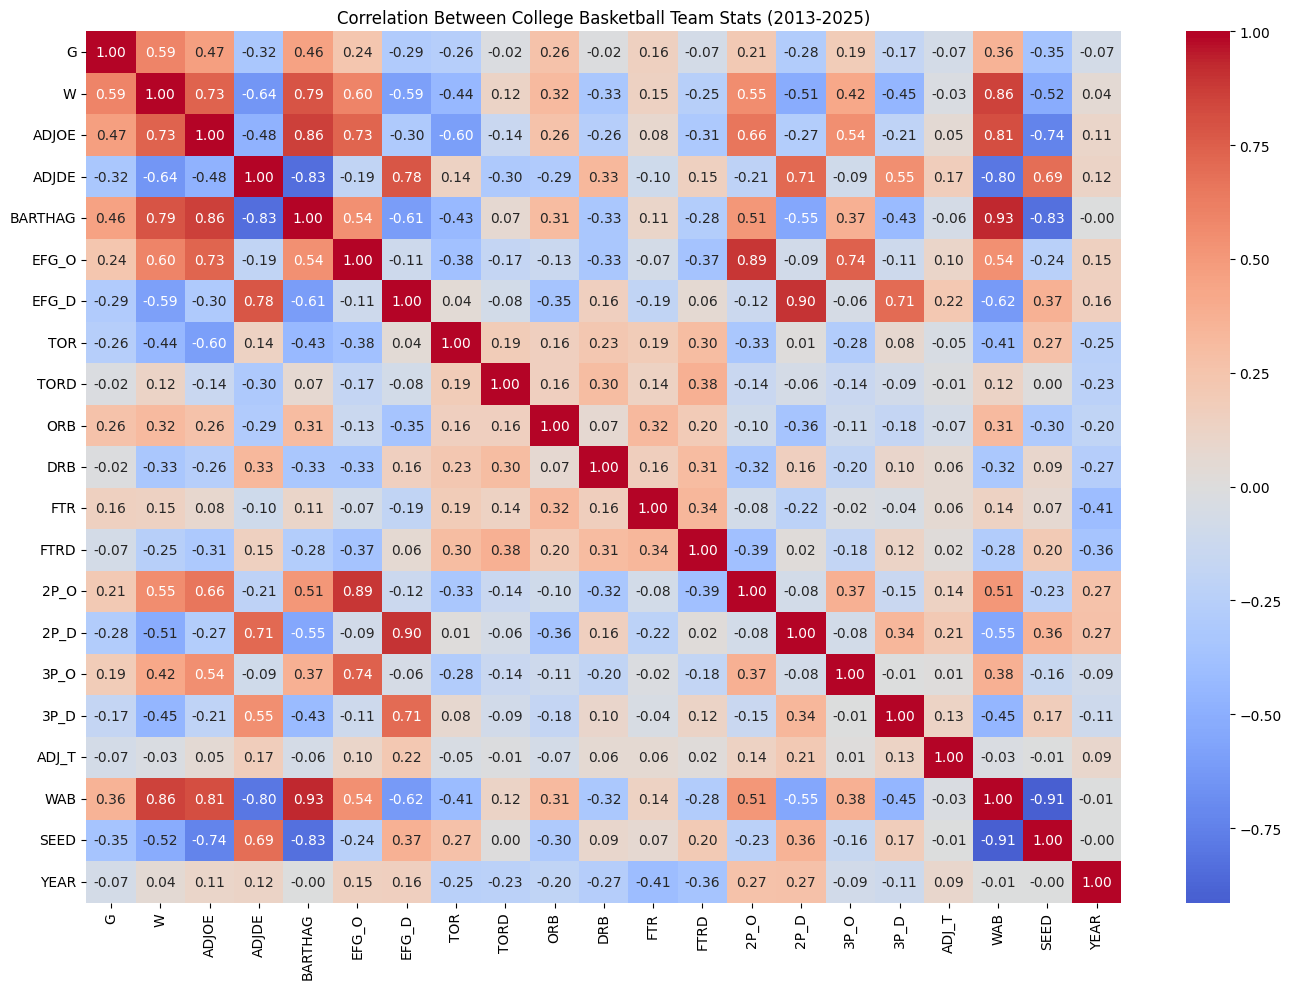

In [ ]:
import os
import kagglehub
import pandas as pd
kagglehub.dataset_download('andrewsundberg/college-basketball-dataset')

dataset_dir = '/root/.cache/kagglehub/datasets/andrewsundberg/college-basketball-dataset/versions/11'
csv_path = os.path.join(dataset_dir, 'cbb.csv')

df = pd.read_csv(filepath_or_buffer=csv_path)


# Finding the total number of observations in this dataset
print(df.info())

# Finding the seasons included in this dataset
print(sorted(df["YEAR"].unique()))

#Printing the first five rows of the dataset to identify what each row is examining
print(df.head())

#Finding the variable names and formats
#This helps to provide whether the data type is an object, int64, or a float64.
#float 64 is numeric data that contains decimals, int64 is whole numerical data, and object data is generally categorical
print(df.dtypes)

#Finding the exact variables names in the dataset

print(df.columns.tolist())

#Seperating the numerical and categorical data types and turning them into lists

print("Categorical variables:")
print(df.select_dtypes(include="object").columns.tolist())

print("\nNumerical variables:")
print(df.select_dtypes(include="number").columns.tolist())


#Key Project Variables from this data set
important_variables = df[
    ["BARTHAG", "POSTSEASON", "SEED", "ADJOE", "ADJDE",
     "EFG_O", "EFG_D", "WAB", "YEAR"]
]

print(important_variables.head())



#Checking missing values in every variable to check for overall data completness
# missing_summary is the variable name where you store your results.


missing_summary = pd.DataFrame({
# Missing Values	Number of missing entries in each variable
# df.isnull() converts the dataset into True and False values indicating missing entries.
    "Missing Values": df.isnull().sum(),
# Percentage Missing is the Percentage of entries missing in each variable
    "Percentage Missing": (df.isnull().mean() * 100).round(2)
})

print ("Missing values by variable:")
display(missing_summary)

#Counting Duplicate Rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Calculating descriptive statistics for numerical variables
descriptive_stats = df.describe().T
# Display the results
display(descriptive_stats)



#Examining the Categorical Variables
# Count teams by conference
print("Teams by conference:")
display(df["CONF"].value_counts())

# Count postseason outcomes, including missing values
# The dropna=False argument tells Python to include missing postseason values in the counts.
print("\nPostseason outcomes:")
display(df["POSTSEASON"].value_counts(dropna=False))

# Count observations for each season
# The .sort_index() method arranges the seasons in numerical order.
print("\nObservations by season:")
display(df["YEAR"].value_counts().sort_index())


#Correlation Map Creation among numerical stattistics in the dataset
import matplotlib.pyplot as plt
import seaborn as sns

#selecting all the numerical variables within the dataset
numeric_df = df.select_dtypes(include="number")

# Calculate correlations between numerical variables
correlation_matrix = numeric_df.corr()

# Creating the heat map
# cmap="coolwarm" uses contrasting colors to show positive and negative correlations, with red showing a strong positive correlation
# annot=True displays the correlation value in each
# Creating the heat map
#cmpa= “coolwarm,” Uses contrasting colors to show positive and negative correlations
#center=0, centers the color scale at zero
# Fmt=’.2f’, rounds each correlation value to 2 decimal places



plt.figure(figsize=(14, 10))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

# Adding a title and displaying the heat map
plt.title("Correlation Between College Basketball Team Stats (2013-2025)")
plt.tight_layout()
plt.show()



Instantiate the SweetViz report and store in memory

In [ ]:
report = sweetviz.analyze(df)

                                             |          | [  0%]   00:00 -> (? left)

Display the report inline


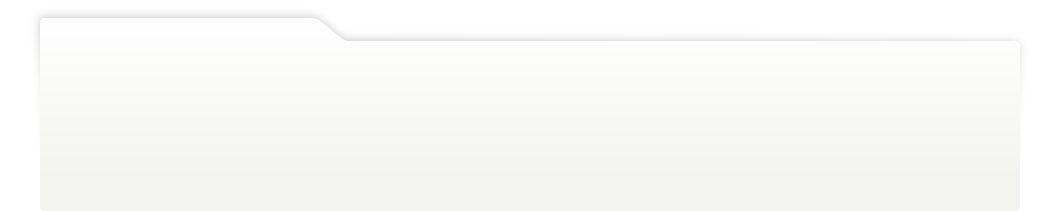
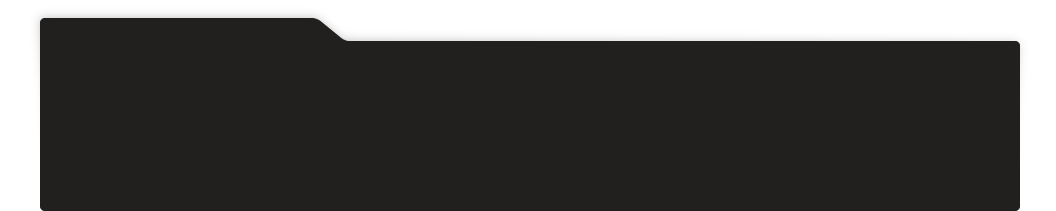
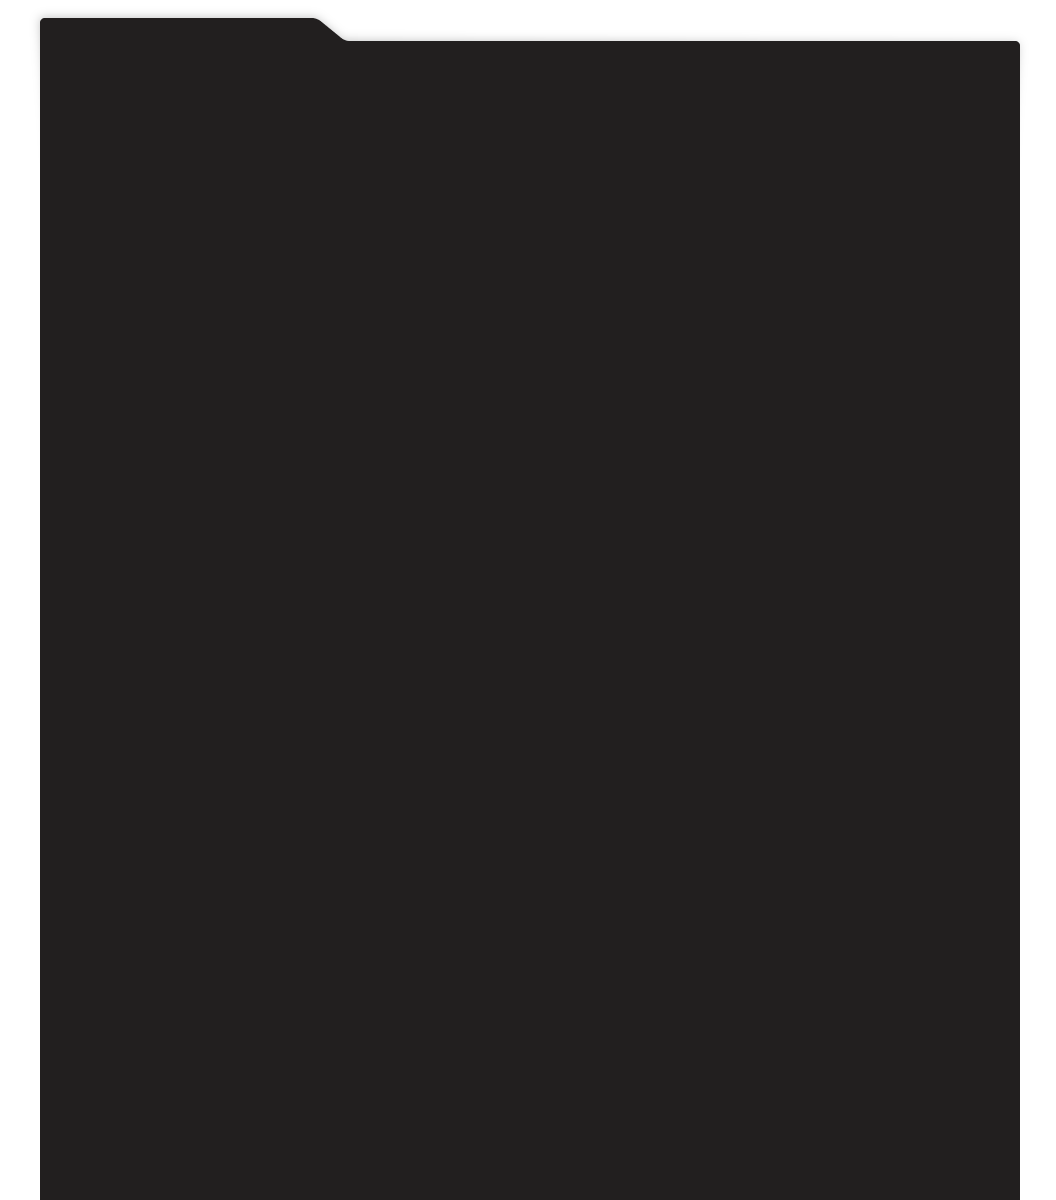
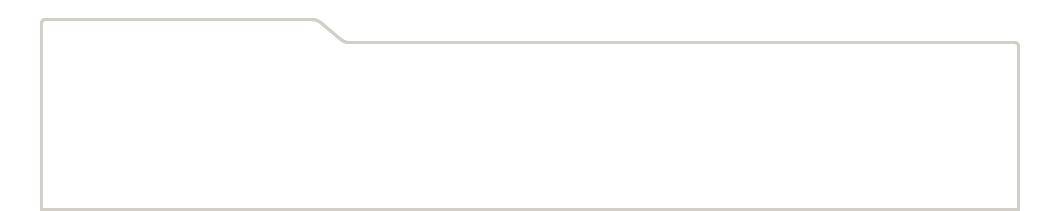
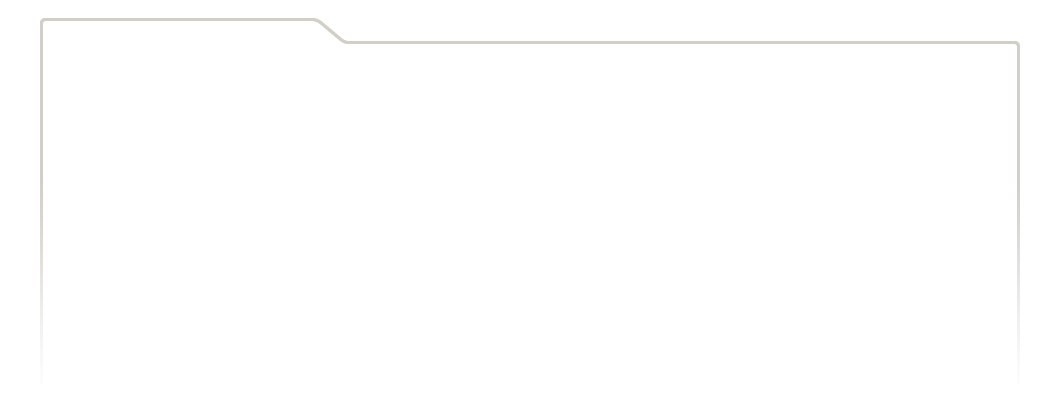
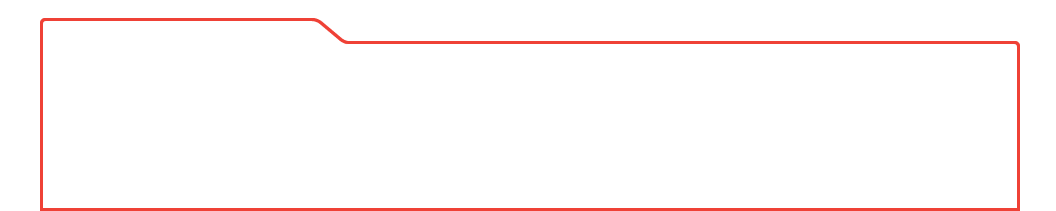
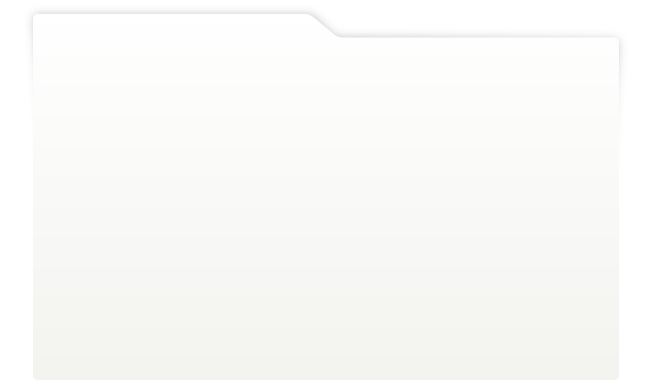
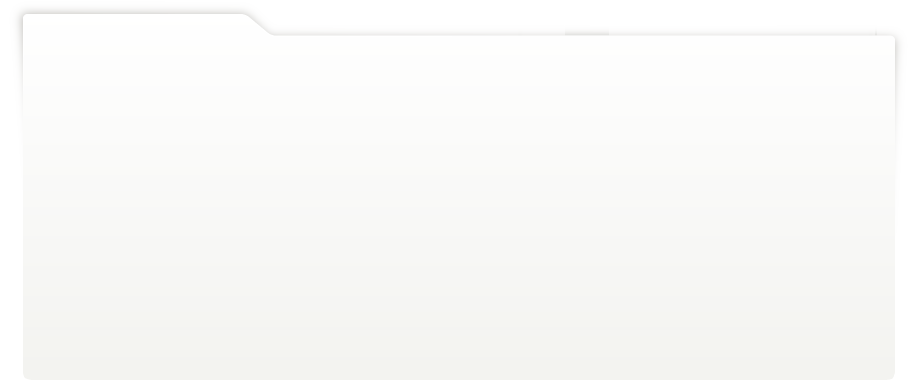
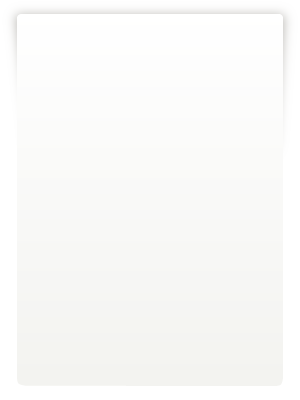
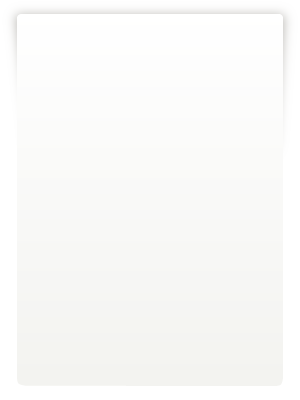
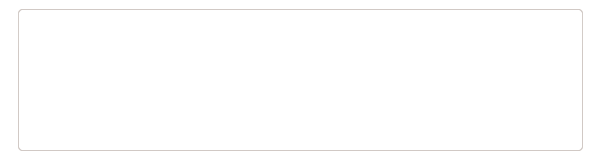
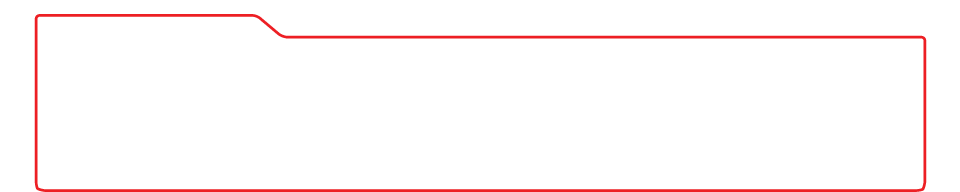
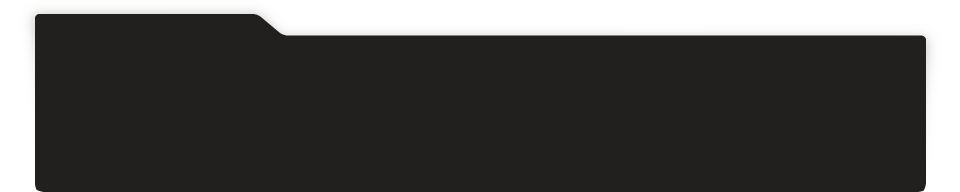
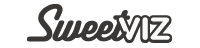
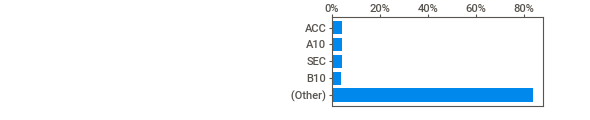
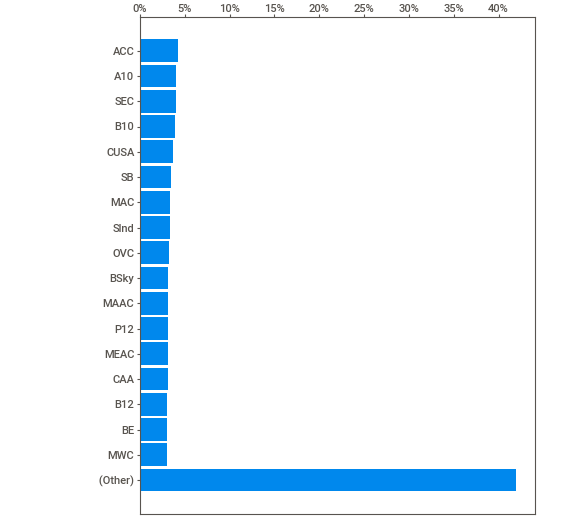
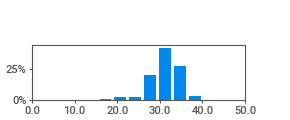
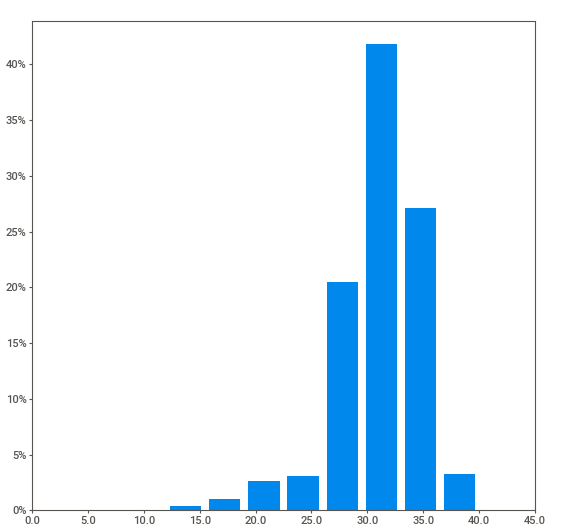
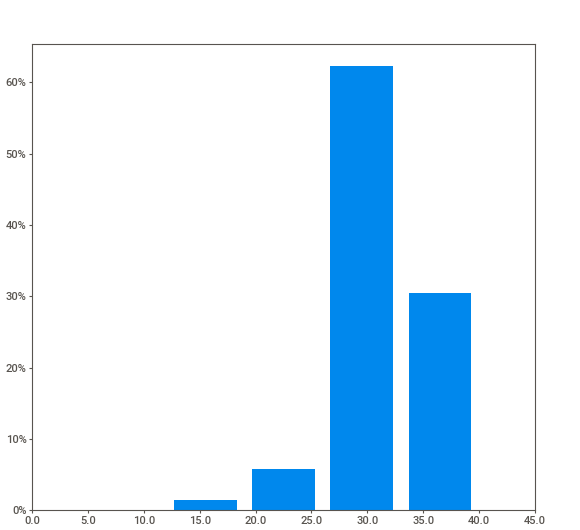
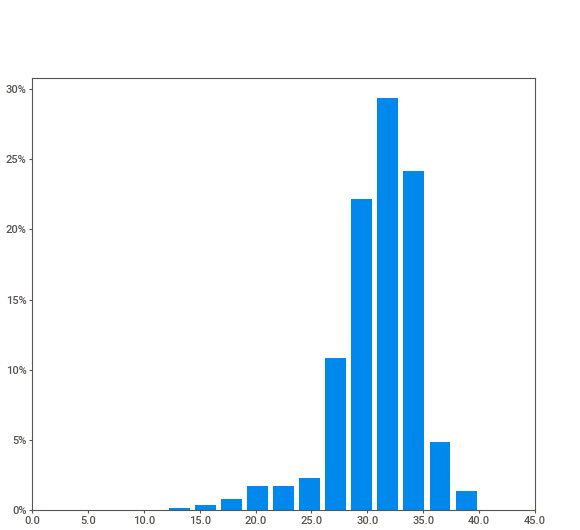
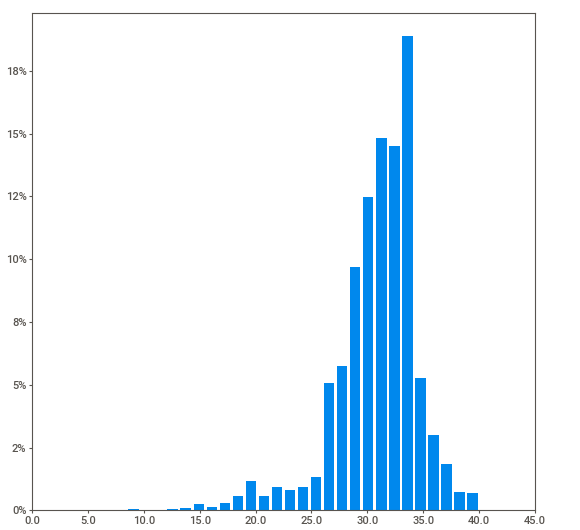
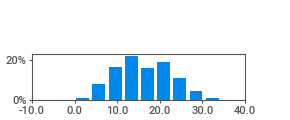
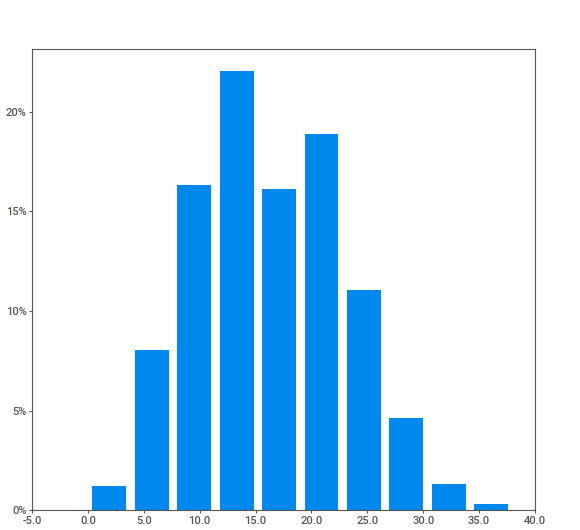
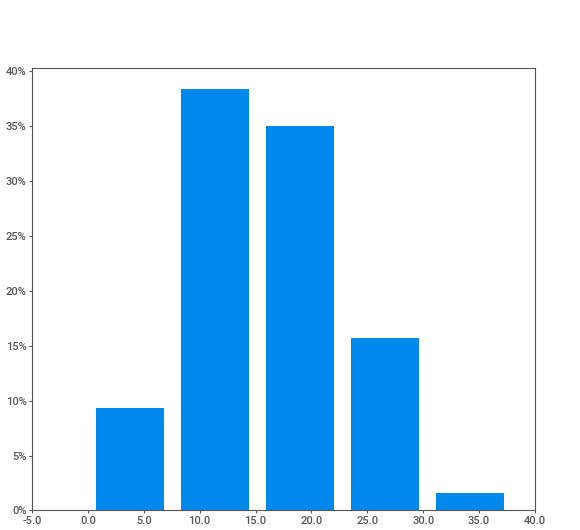
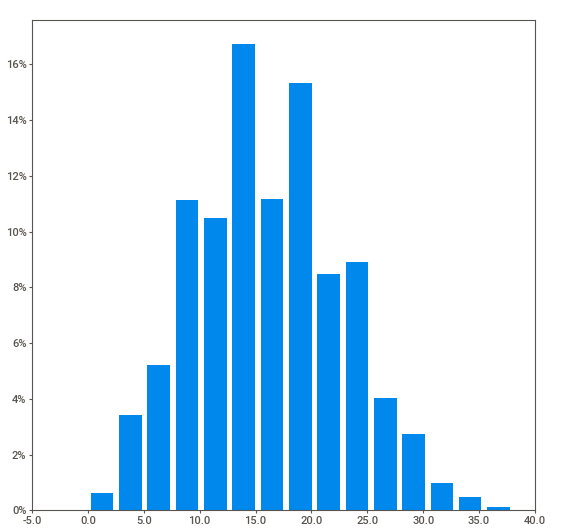
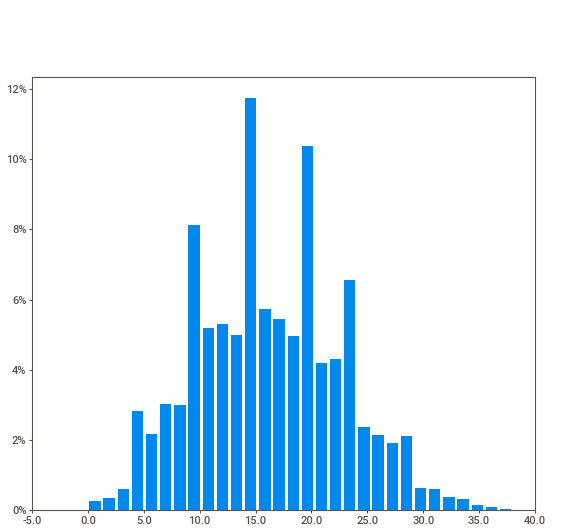
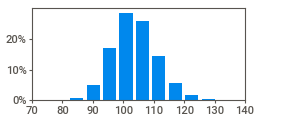
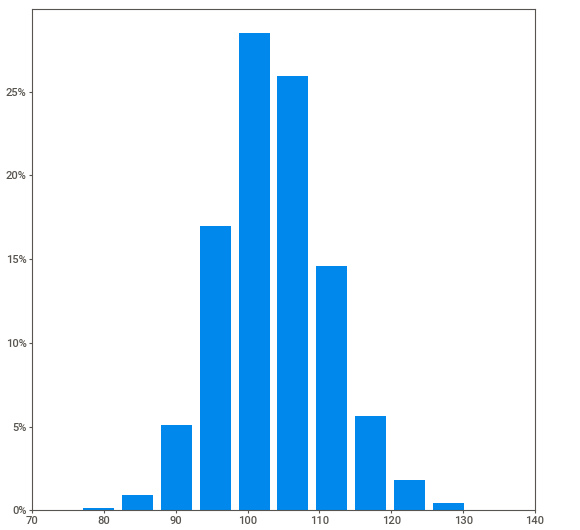
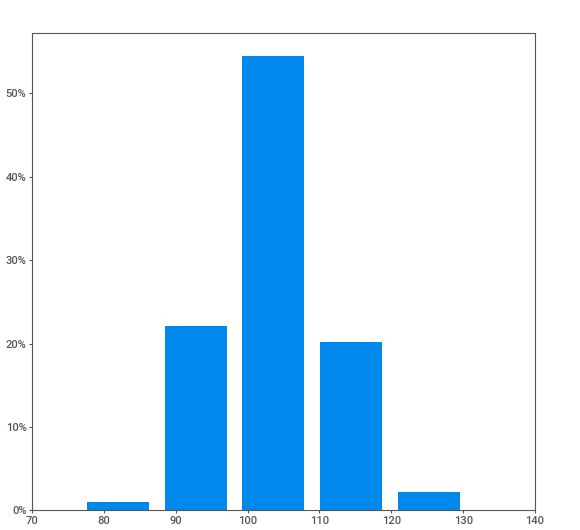
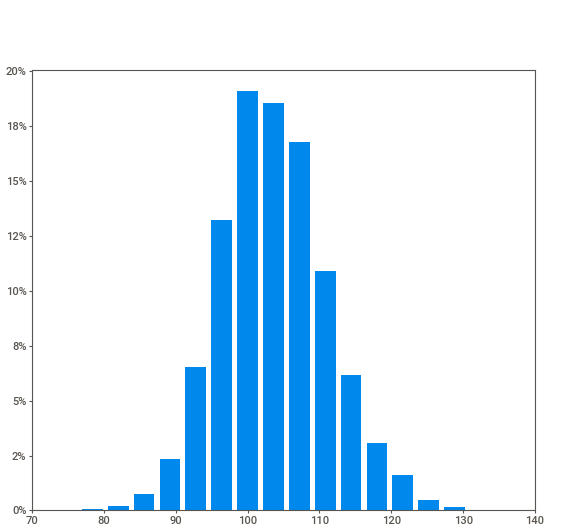
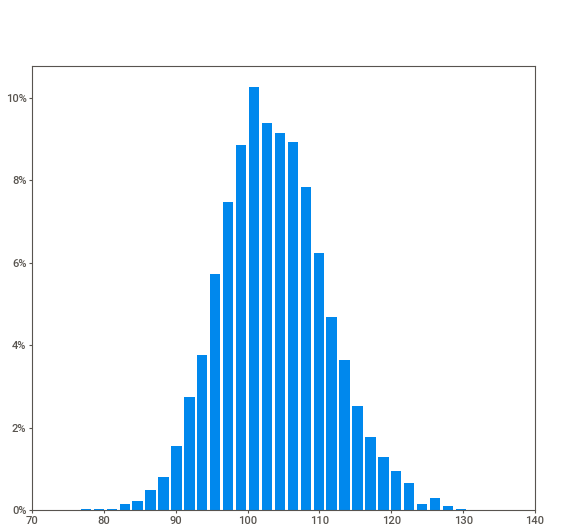
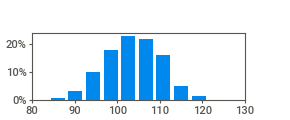
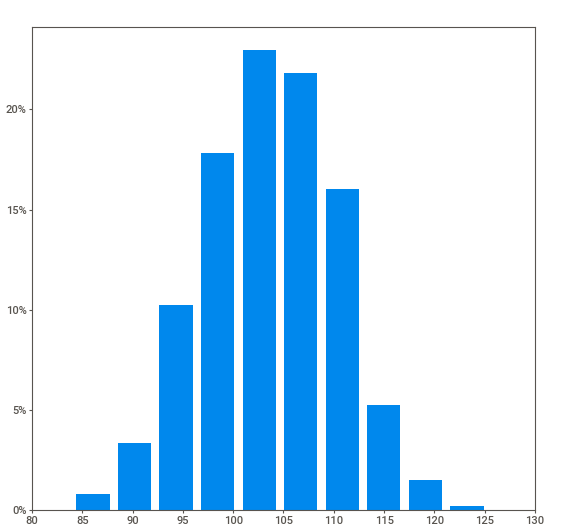
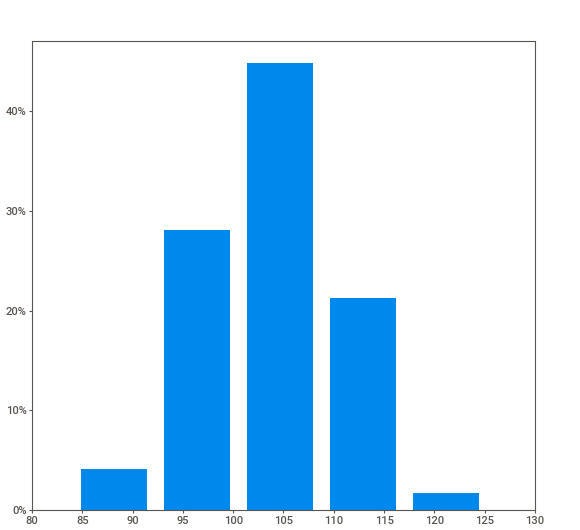
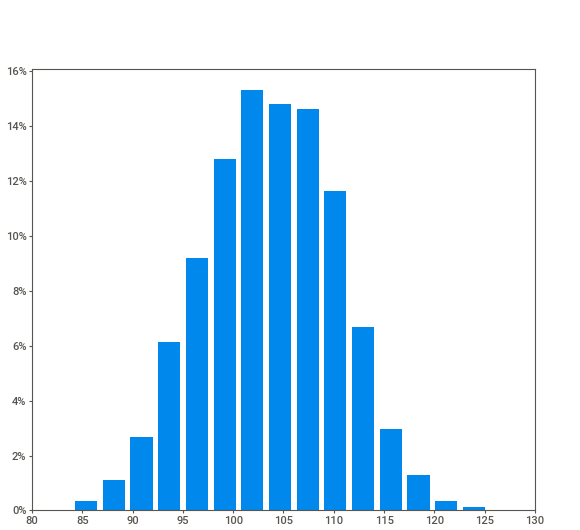
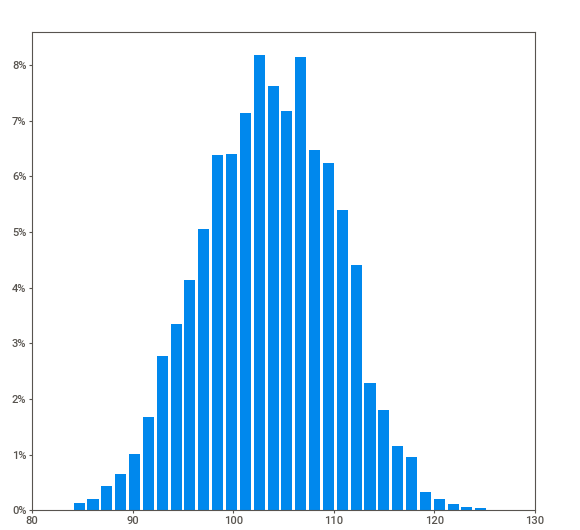
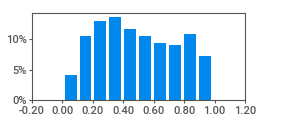
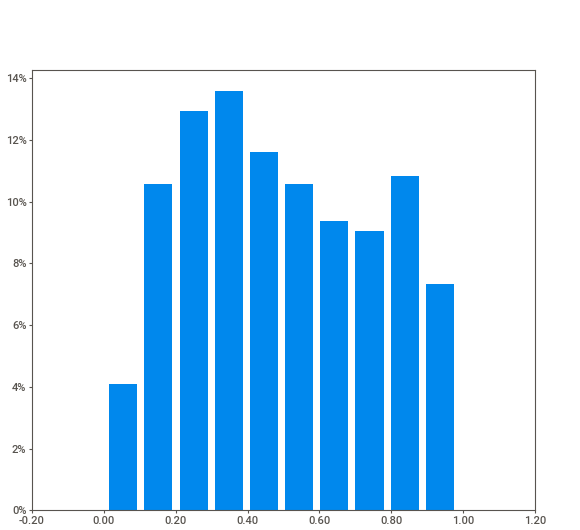
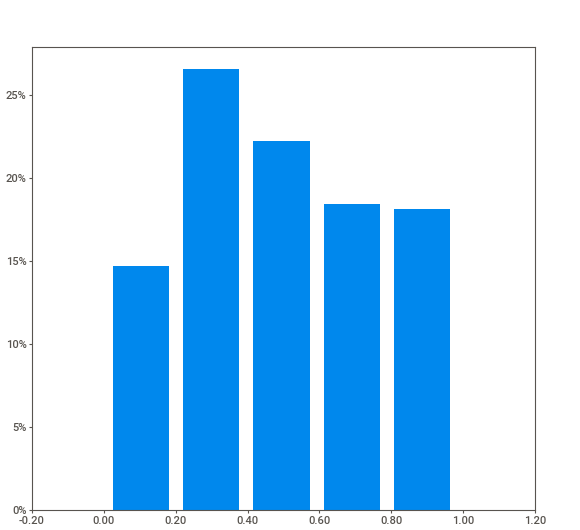
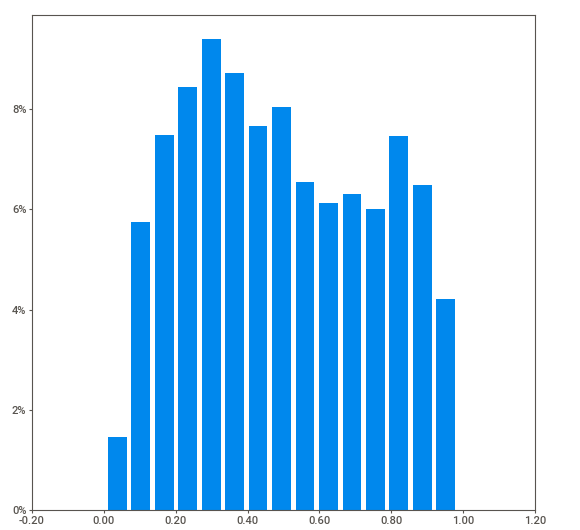
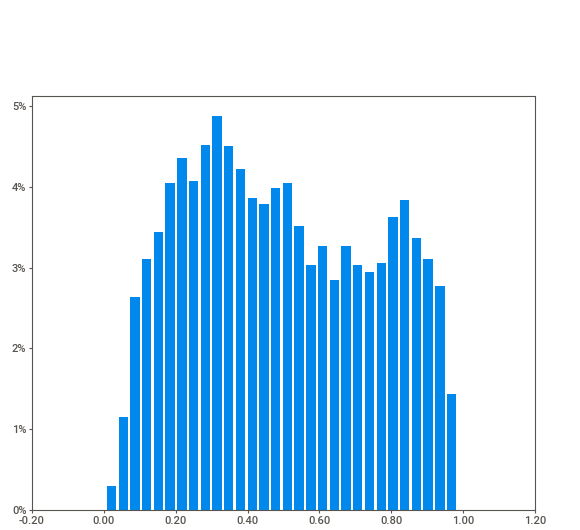
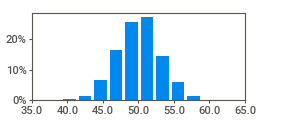
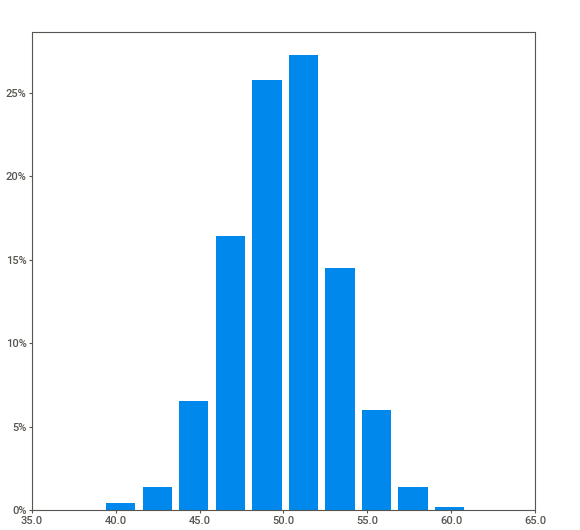
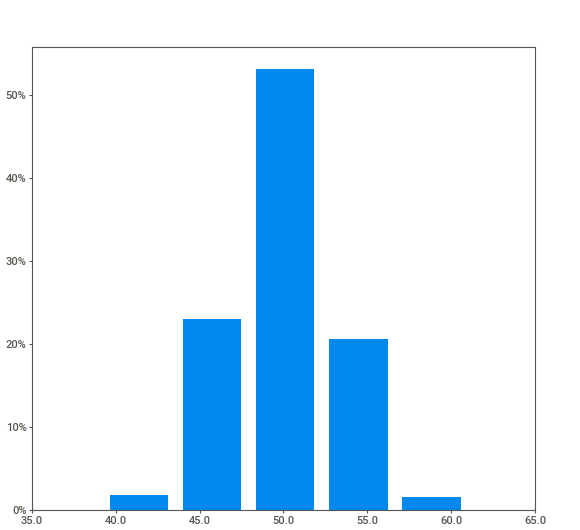
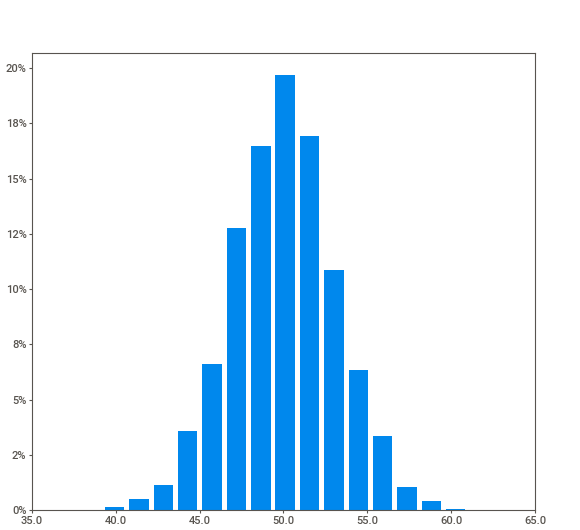
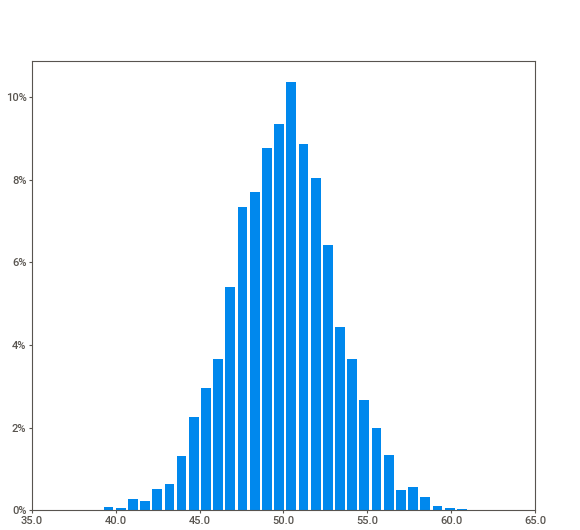
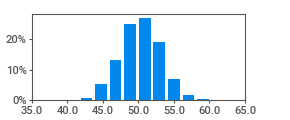
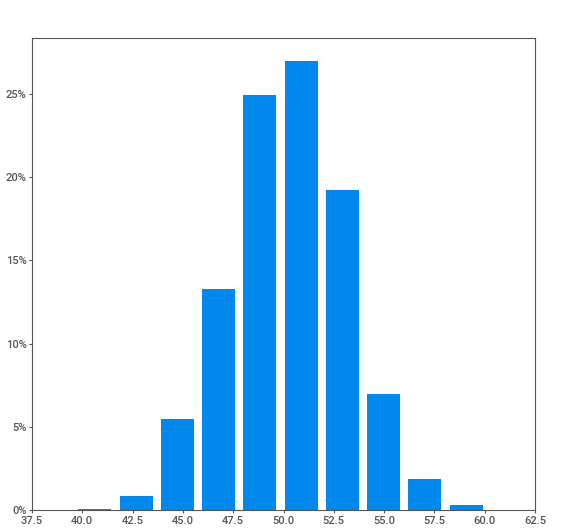
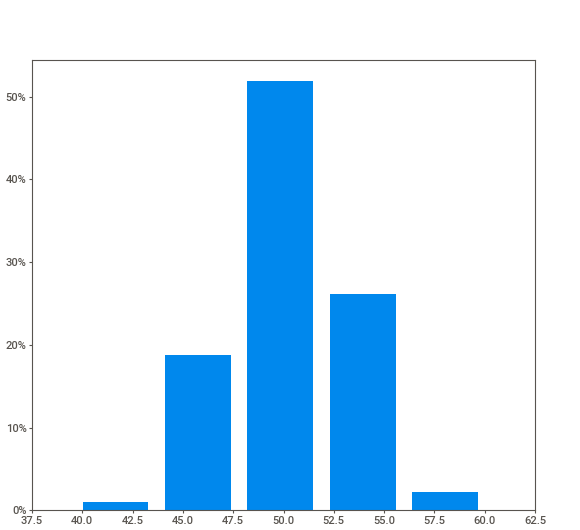
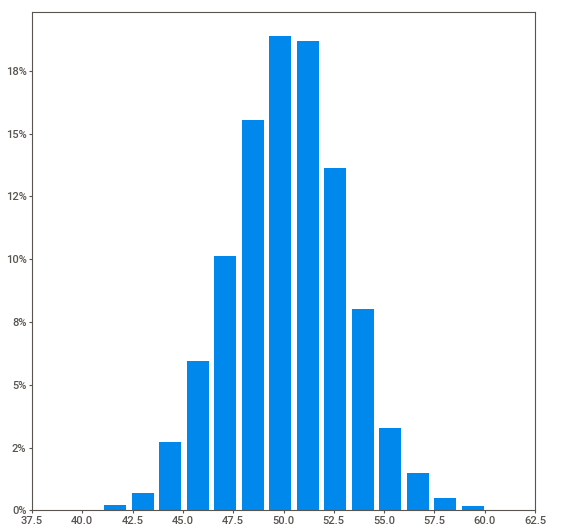
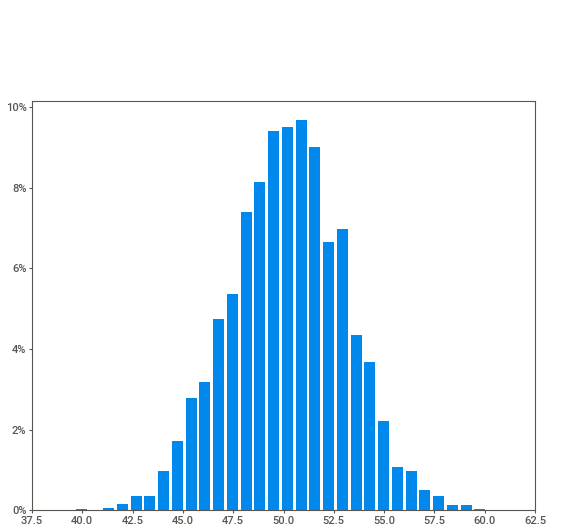
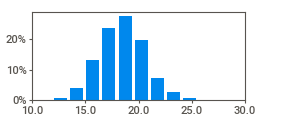
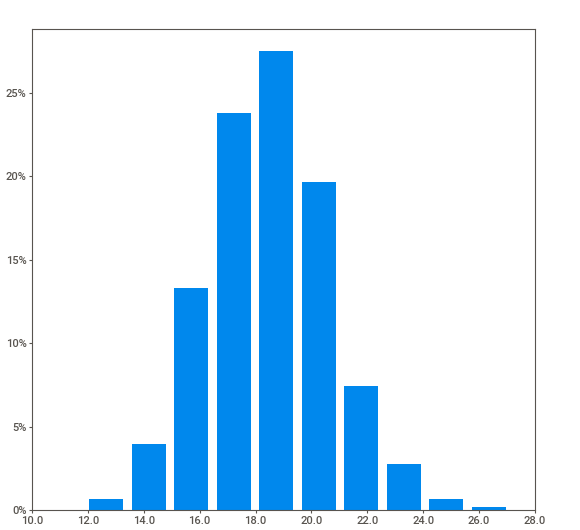
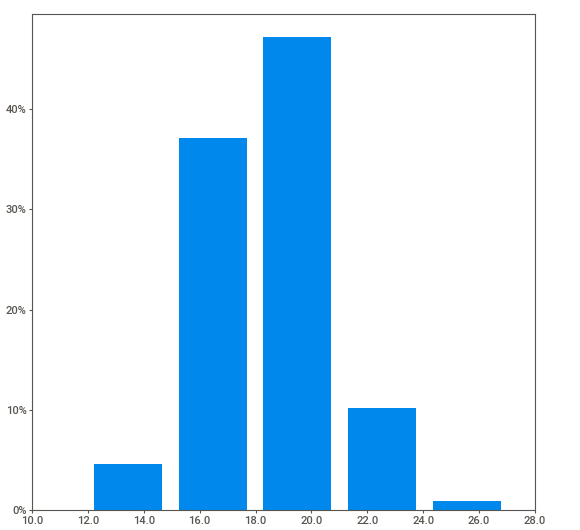
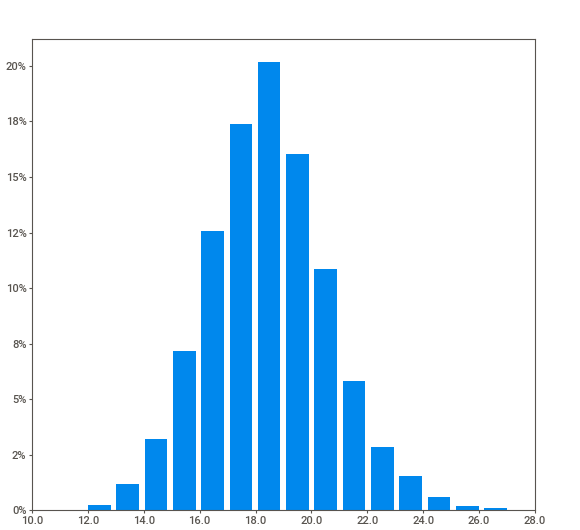
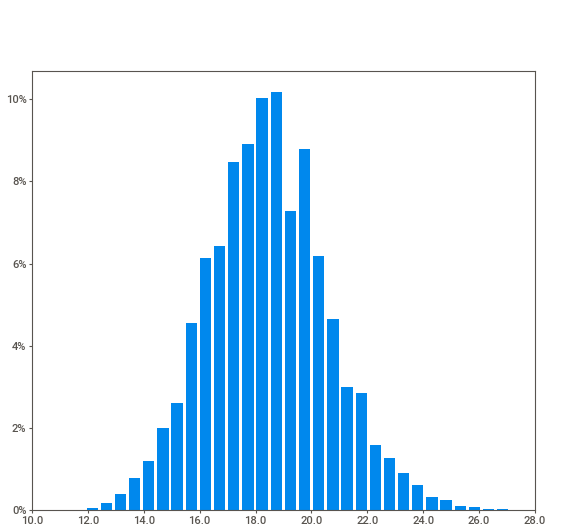
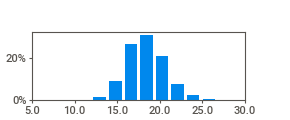
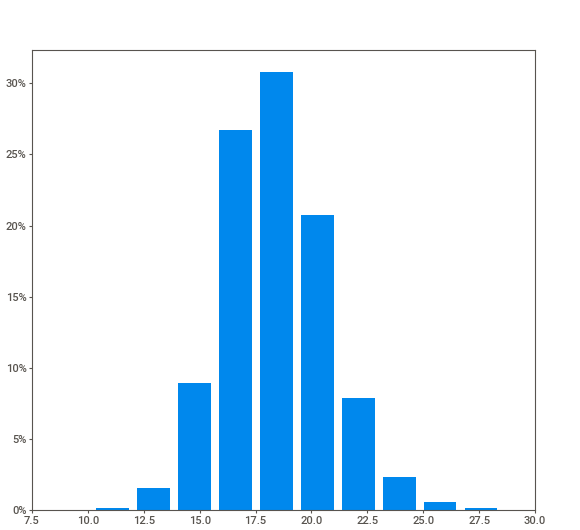
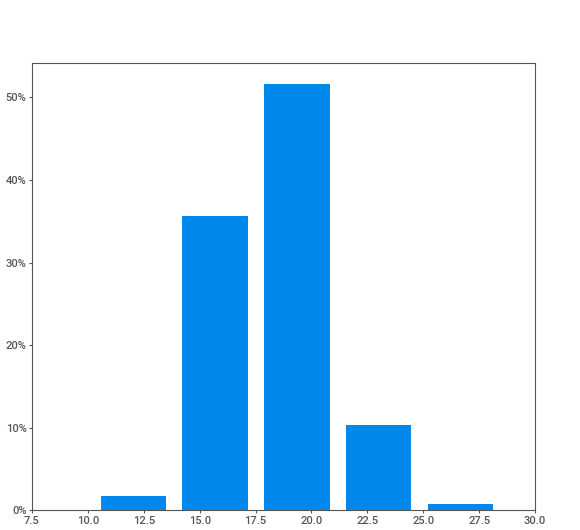
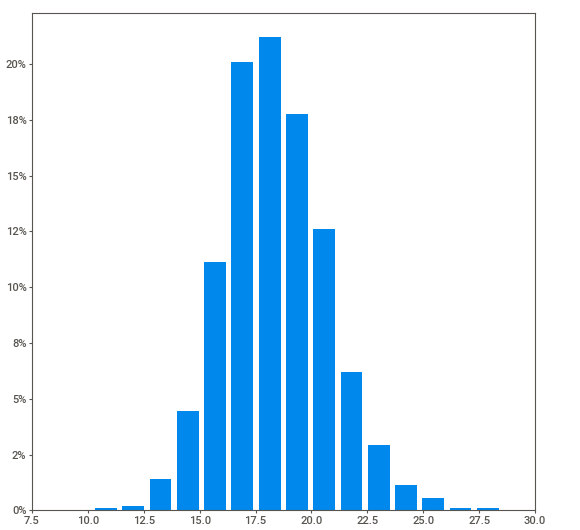
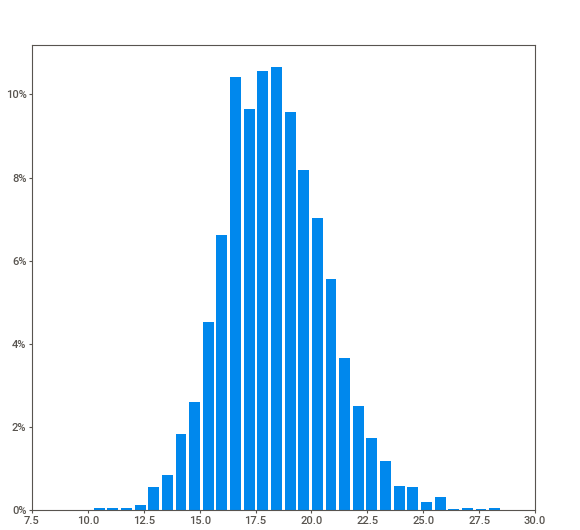
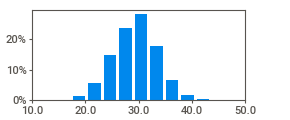
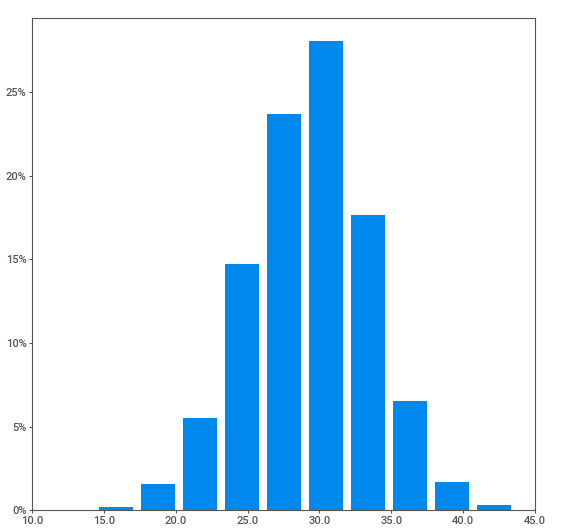
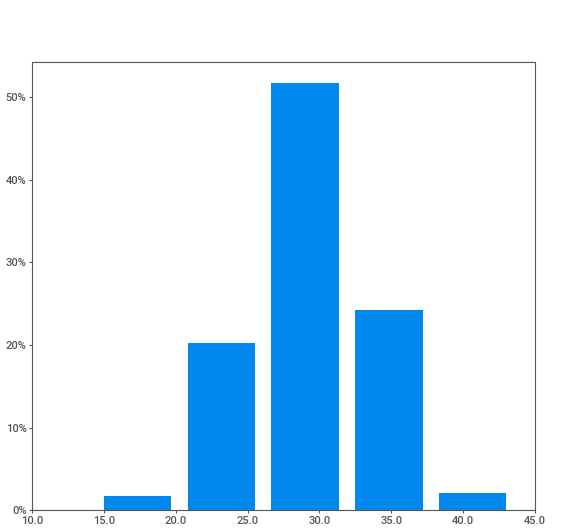
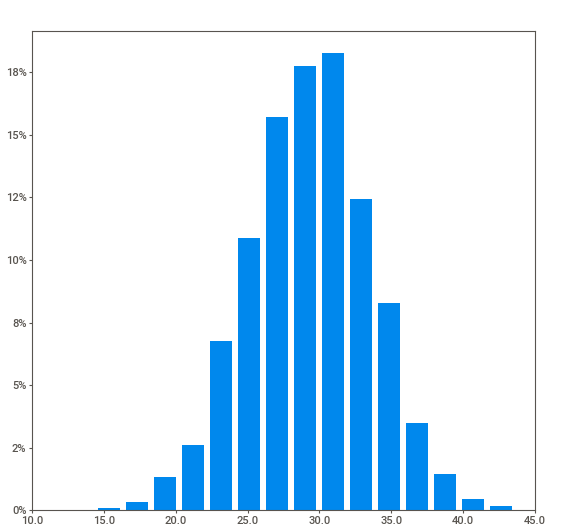
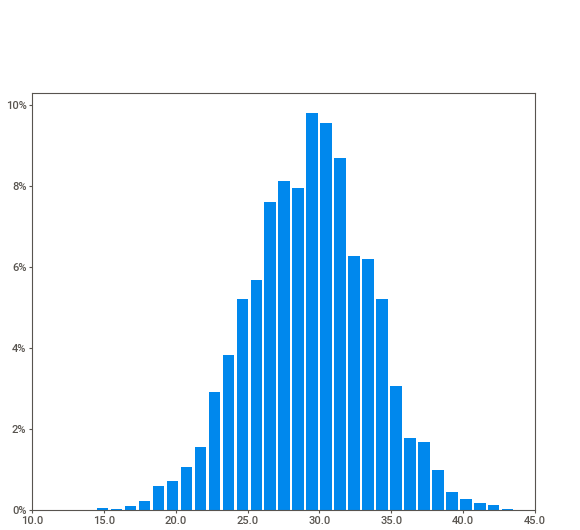
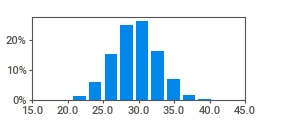
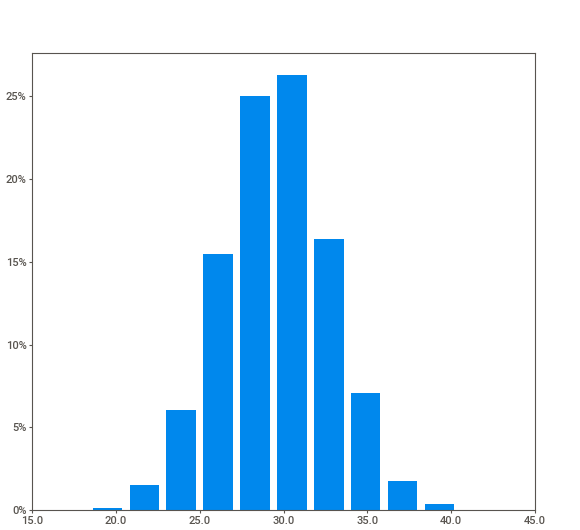
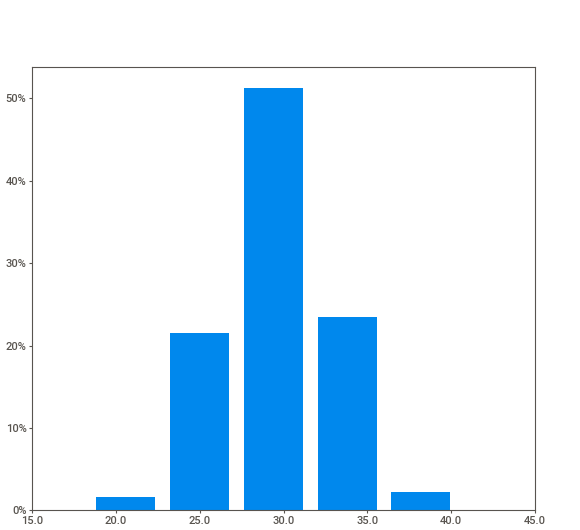
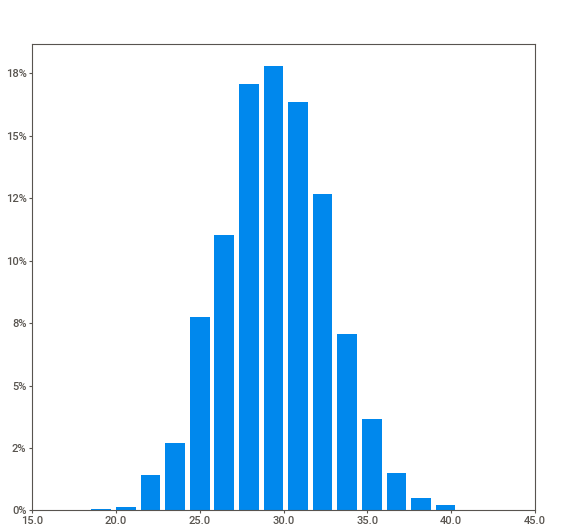
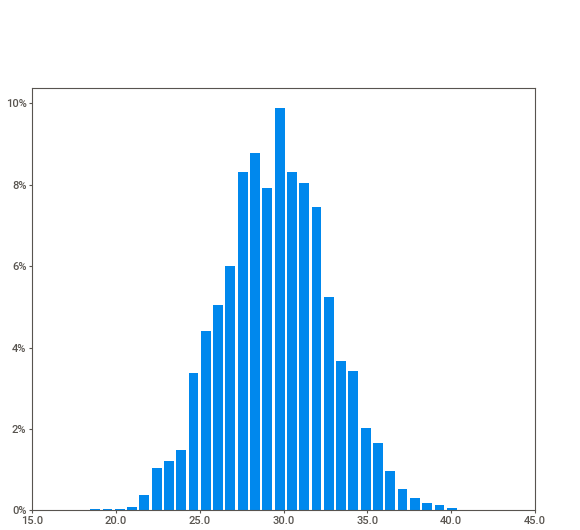
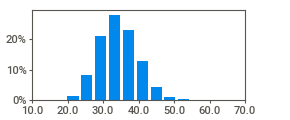
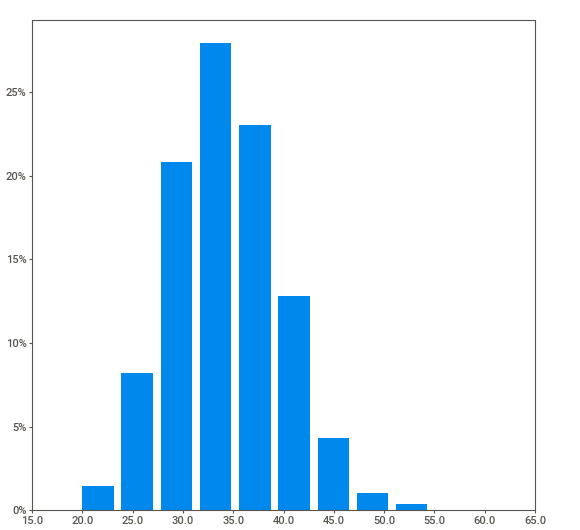
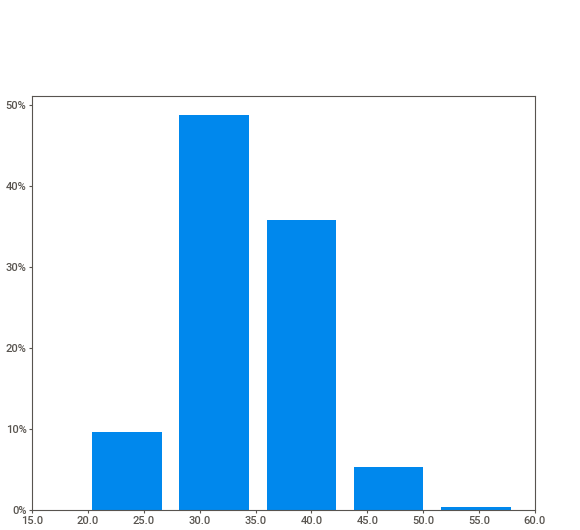
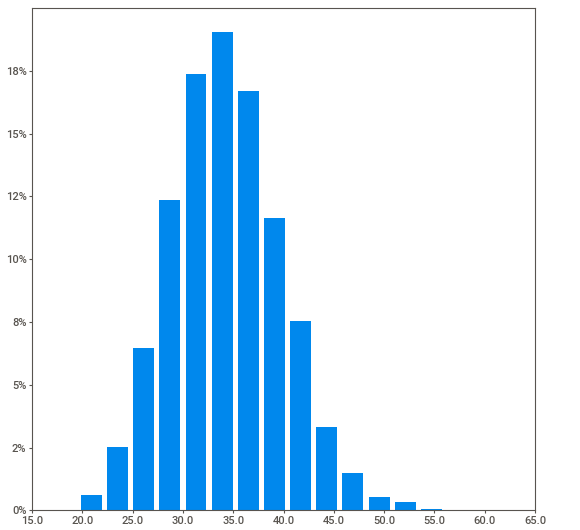
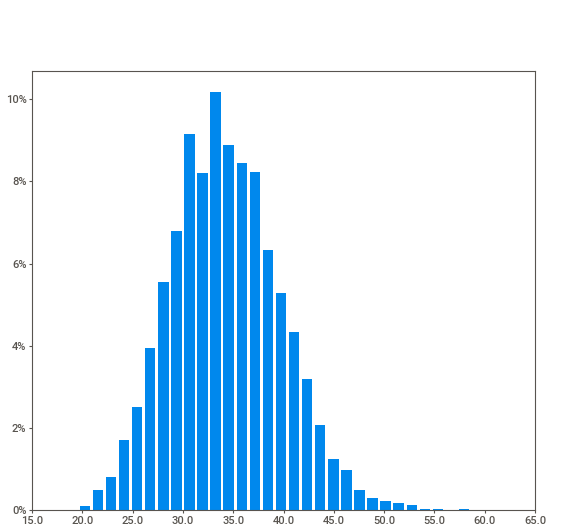
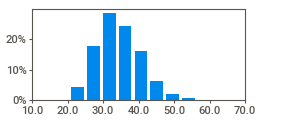
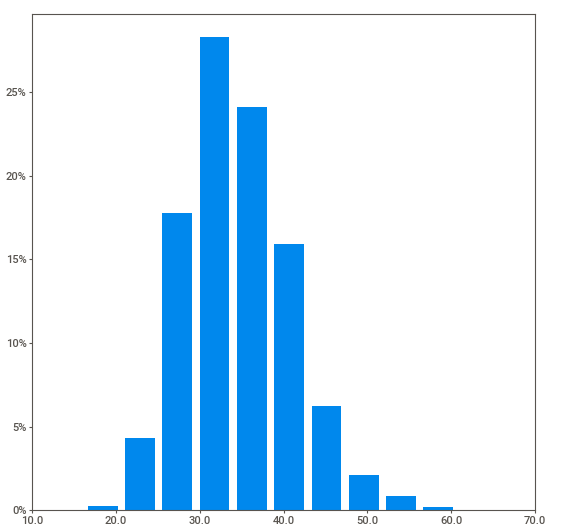
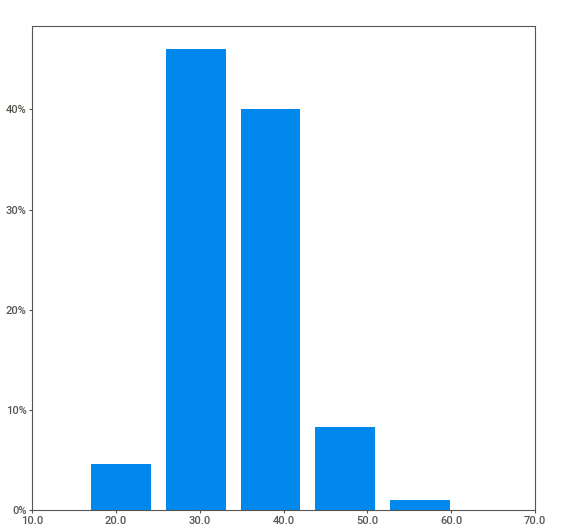
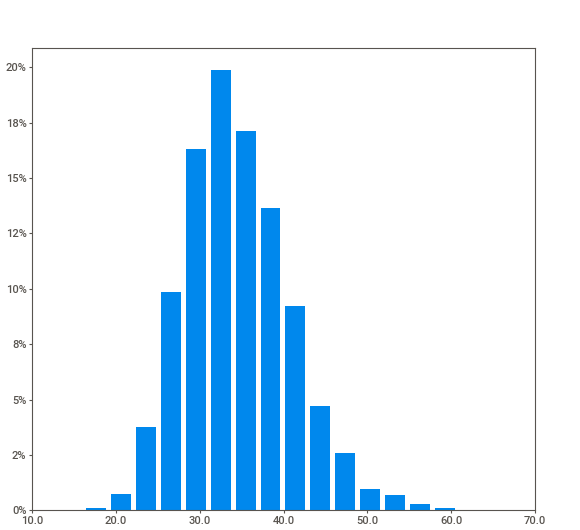
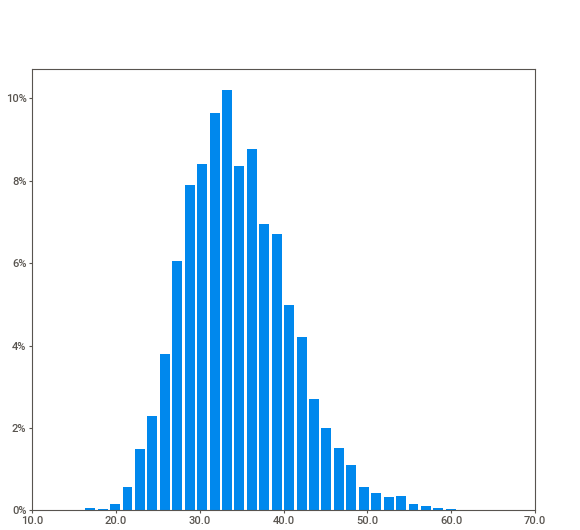
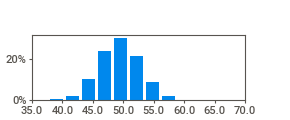
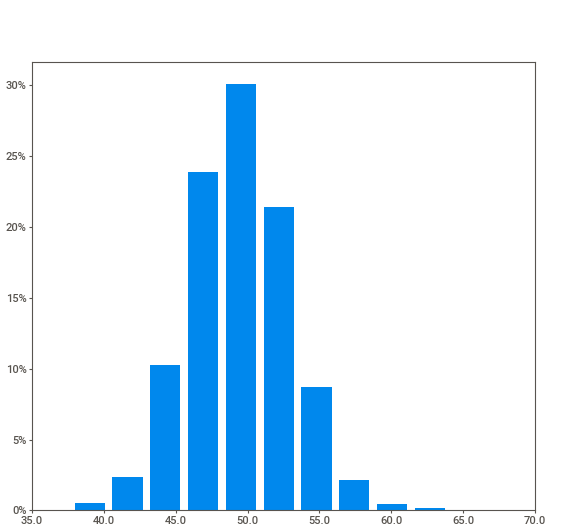
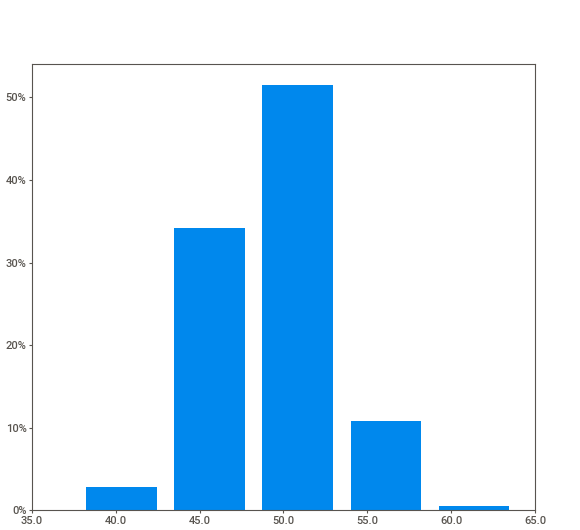
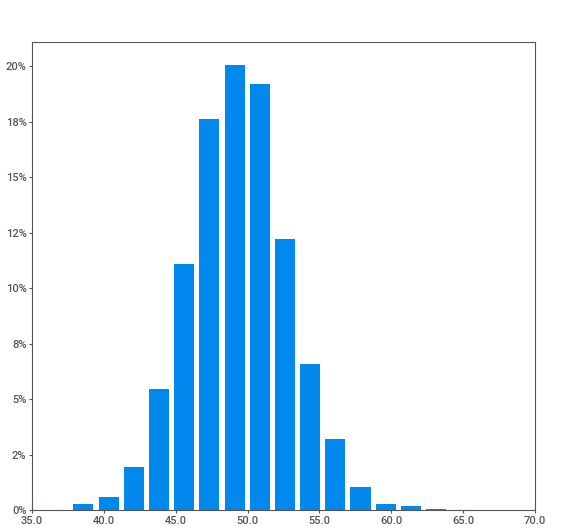
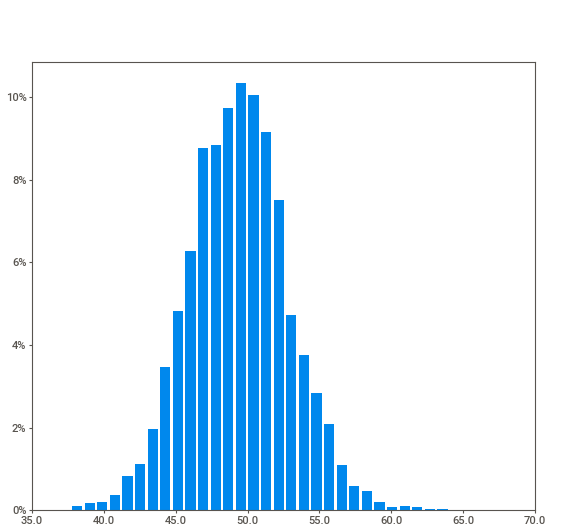
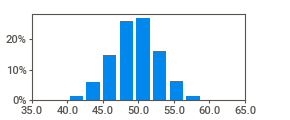
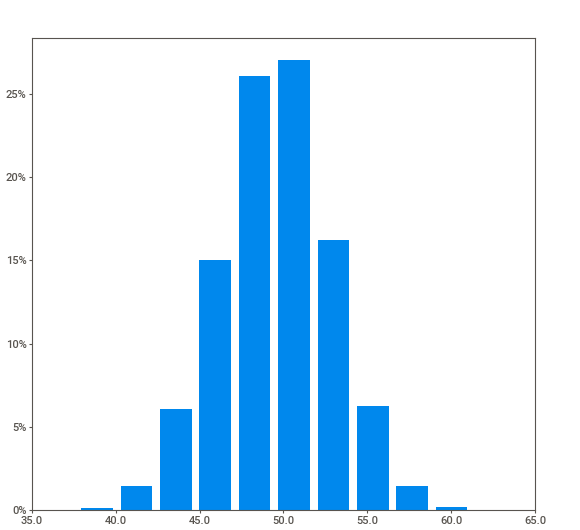
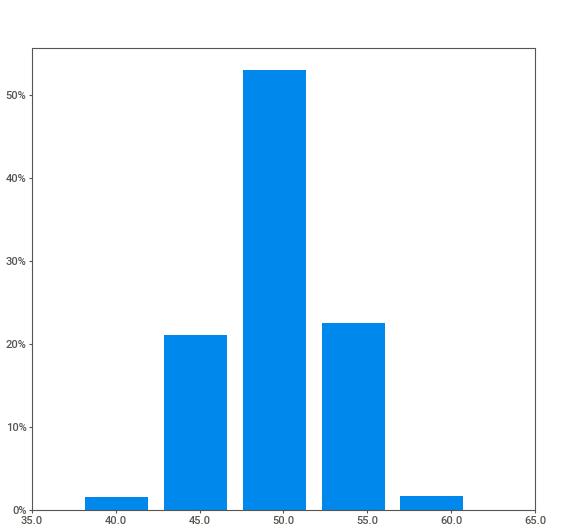
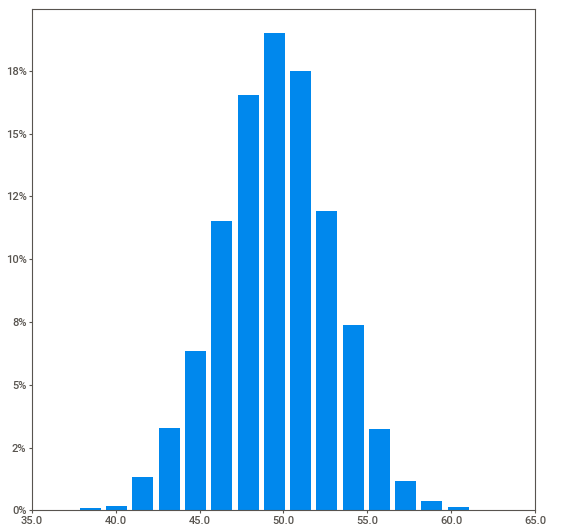
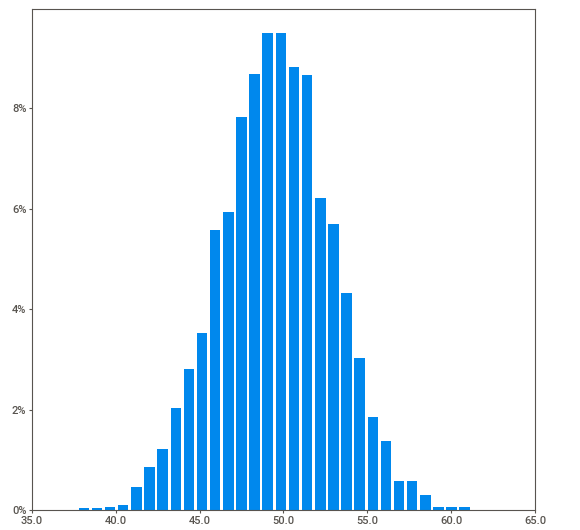
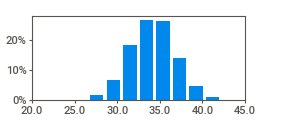
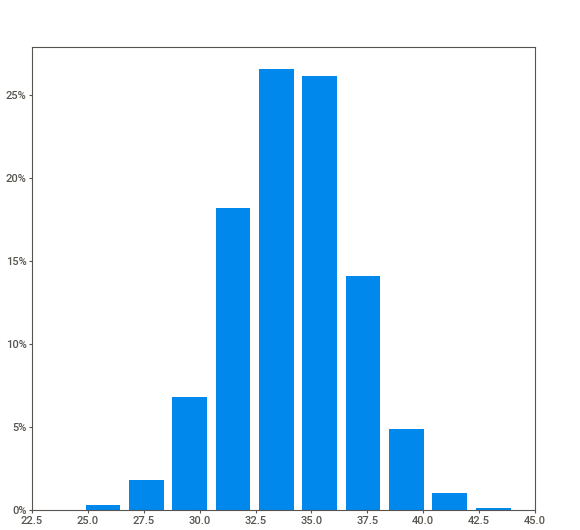
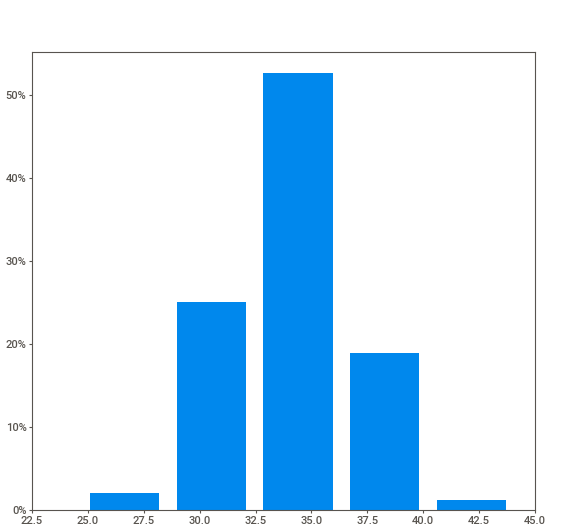
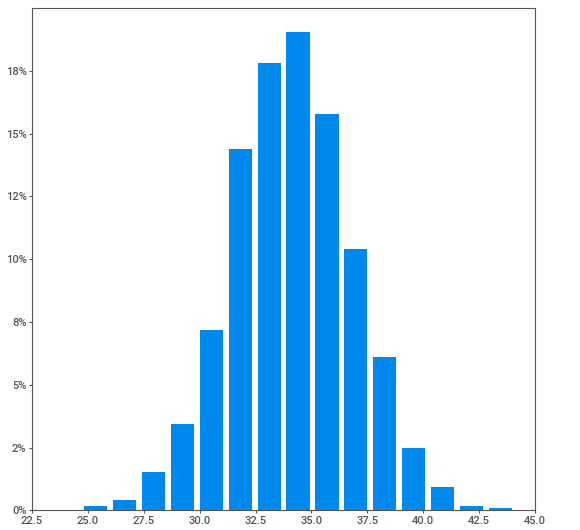
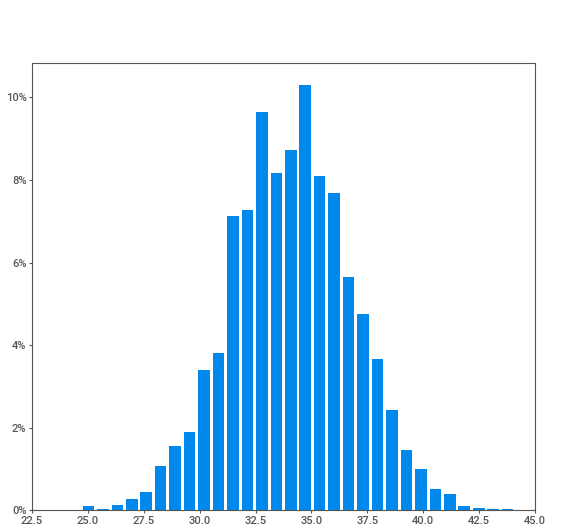
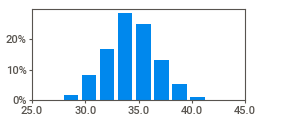
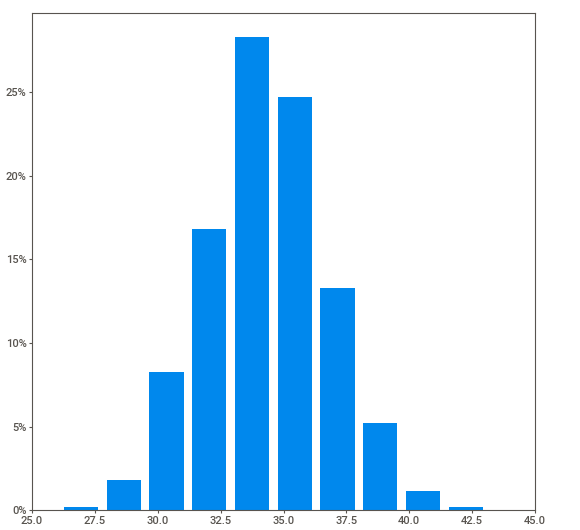
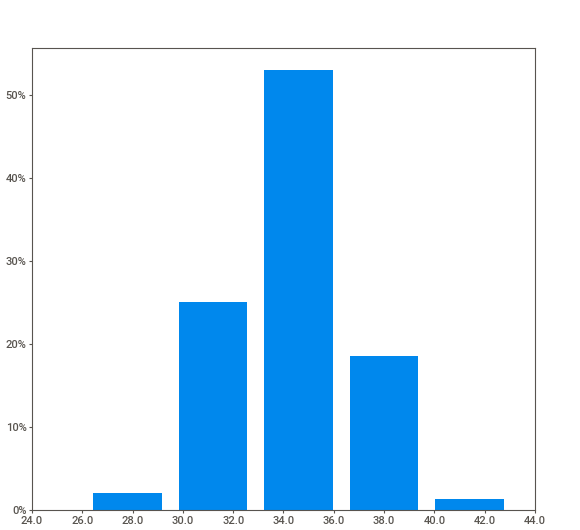
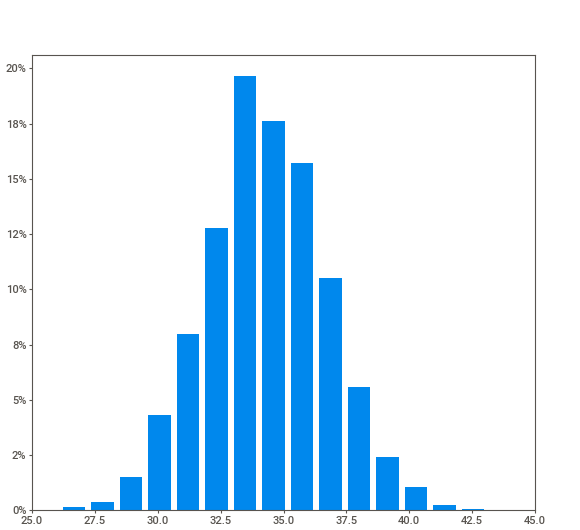
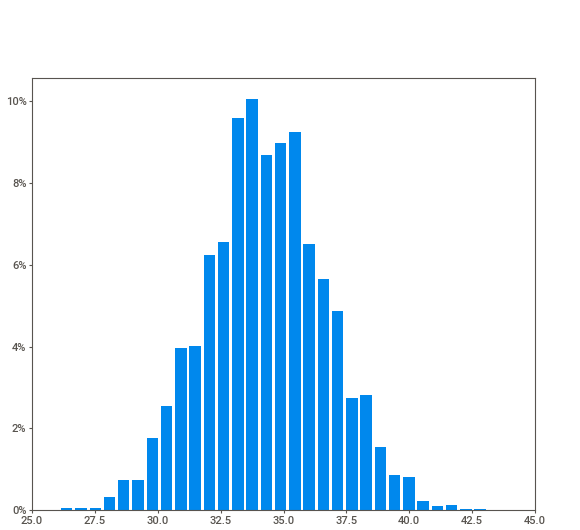
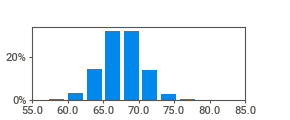
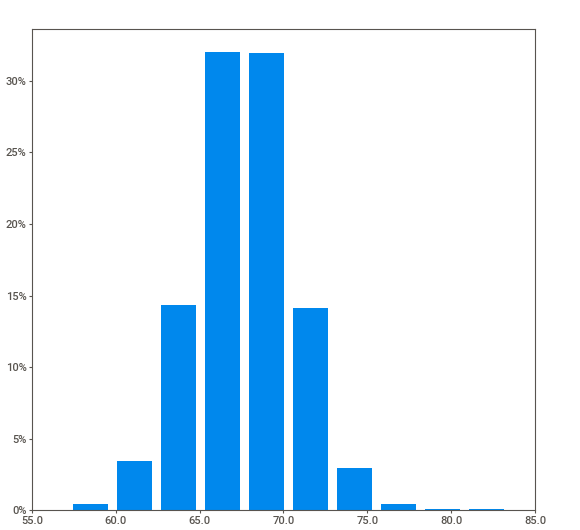
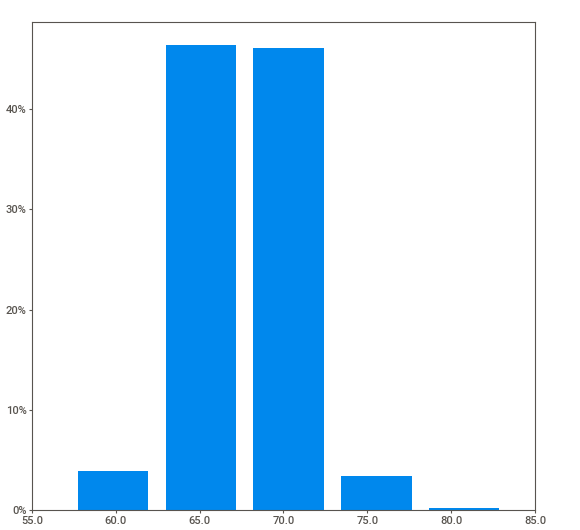
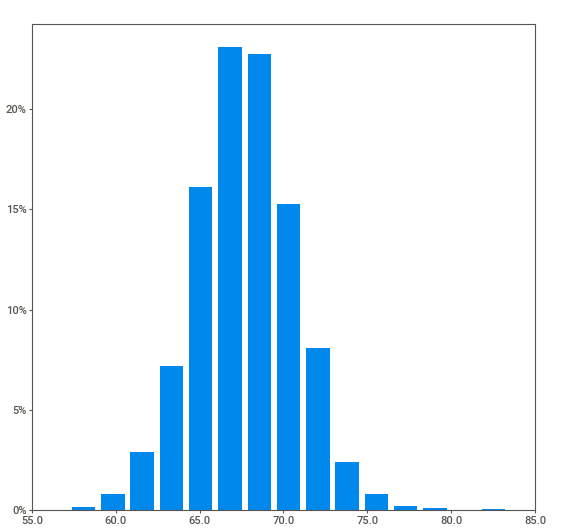
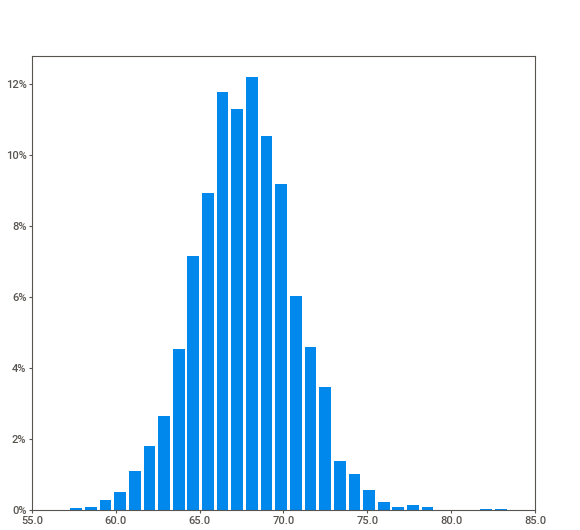
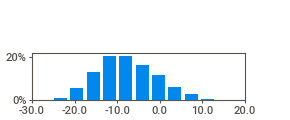
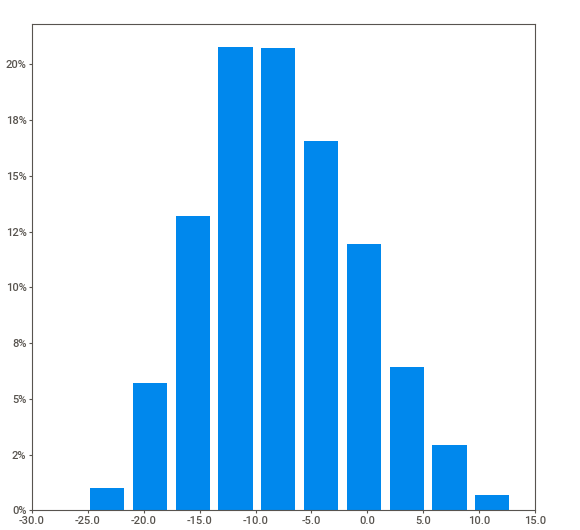
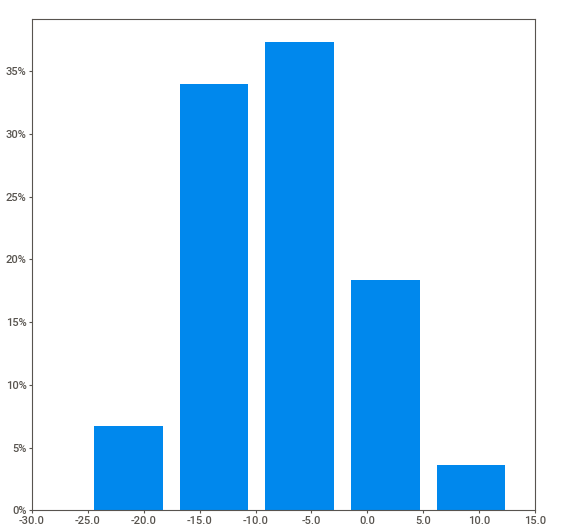
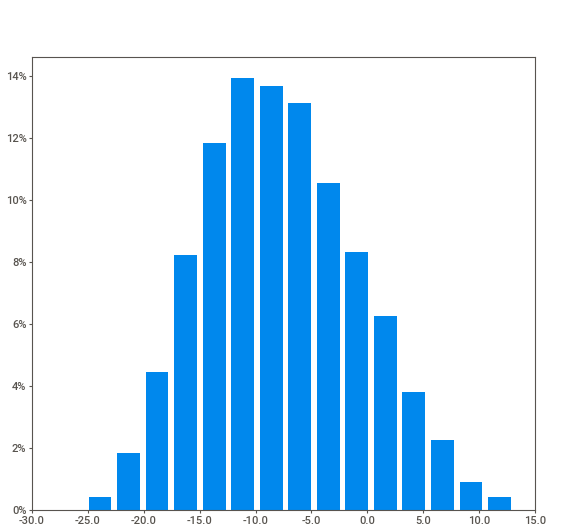
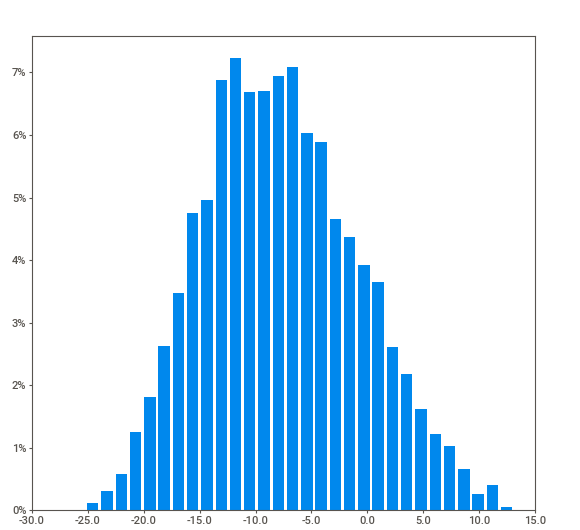
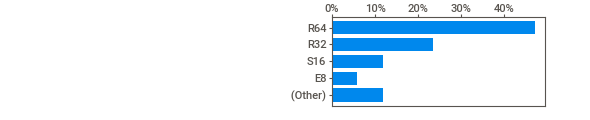
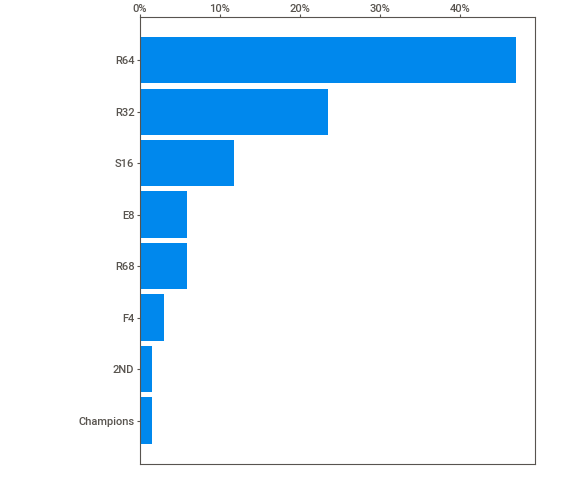
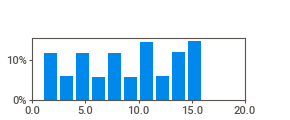
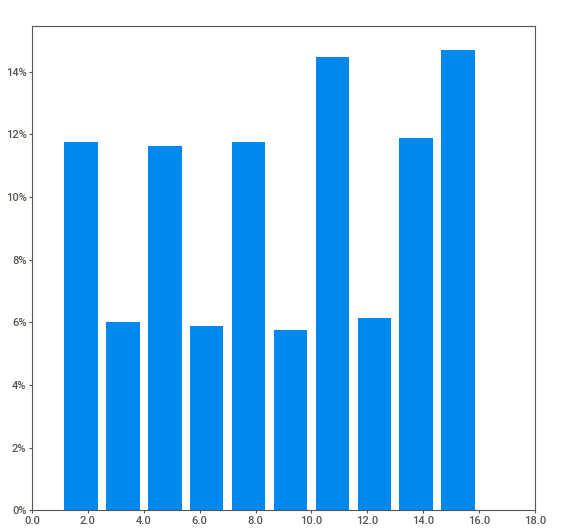
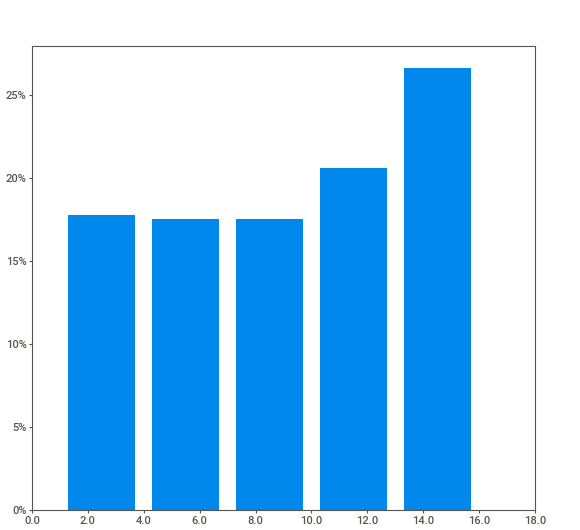
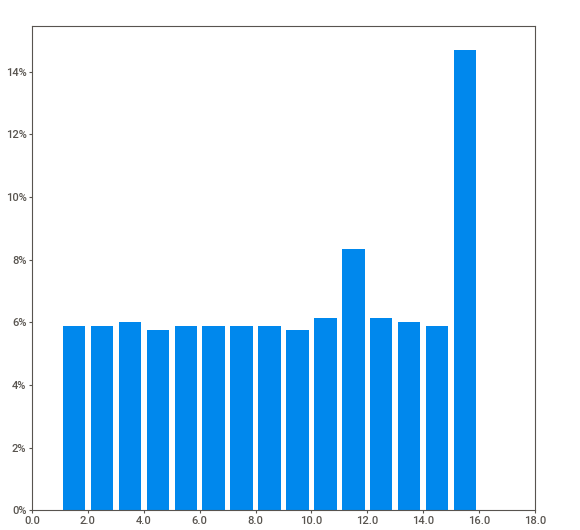
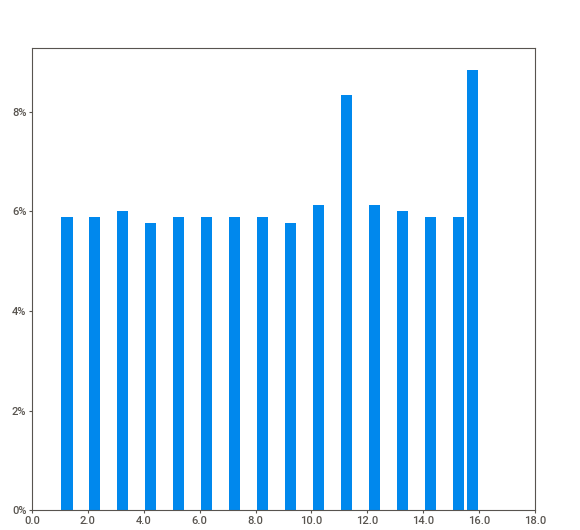
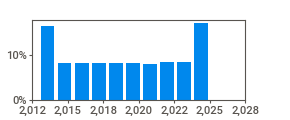
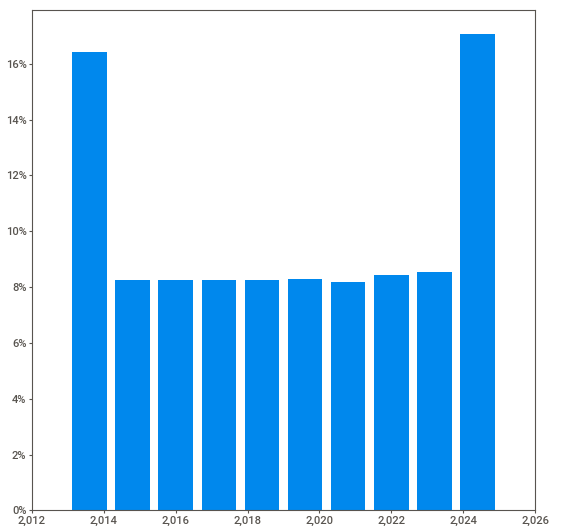
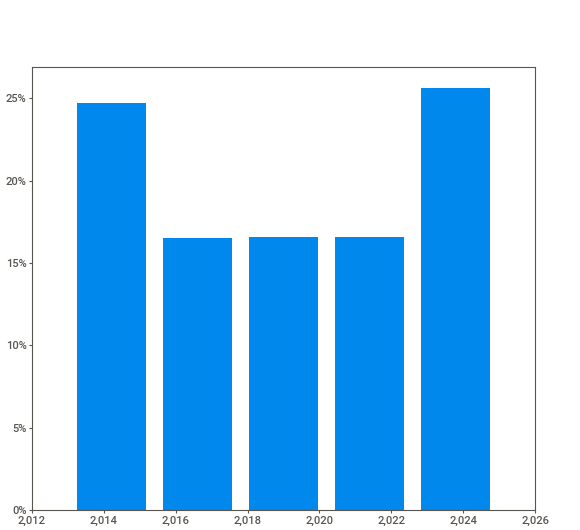
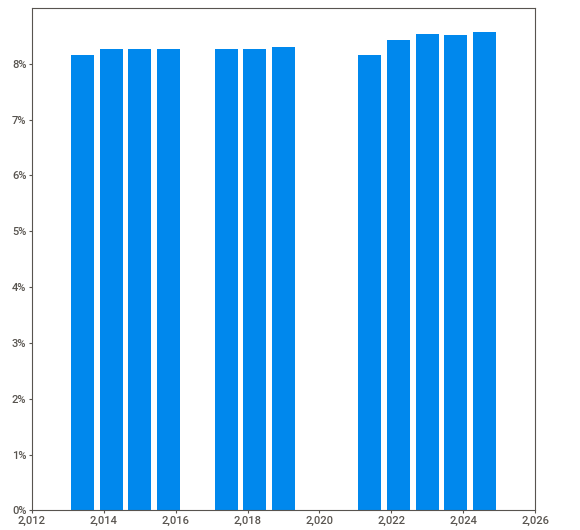
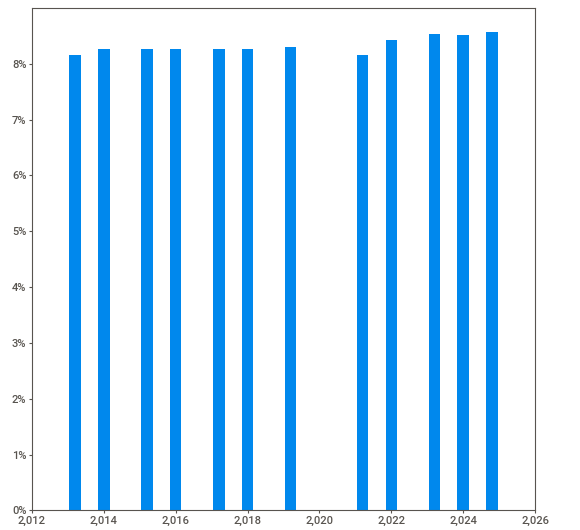
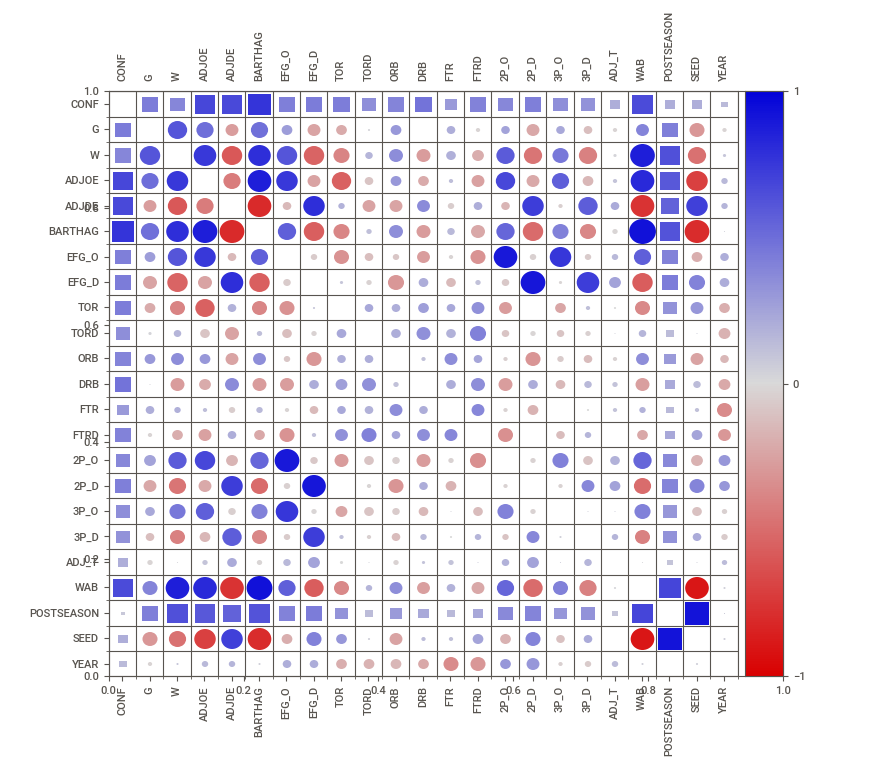
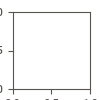

In [ ]:
report.show_notebook()

In [ ]:
report.show_html("report.html")

Report report.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.
